# H3-02 | EDA Notebook ve Veri Kalitesi Analizi

**İlgili issue:** #28 · **Bağımlılık:** H3-01 (#27, PR #77) · **İlgili isterler:** İST-03, İST-13, İST-15, İST-16

## 1. Giriş ve amaçlar

**Keşifsel veri analizi (EDA)**, bir veri kümesinin yapısını, dağılımlarını ve sınırlarını model
veya test üretimi öncesinde nicel olarak ortaya koymayı amaçlar. Bu notebook, H3-01'de hazırlanan
**kontrollü Django/DRF senaryo veri kümesini** (`benchmarks/drf_fixtures/scenarios/scenarios.json`)
inceler.

- **Senaryo kapsamı ve otomatik test üretimi:** AI test ajanının üreteceği Pytest testlerinin
  değerlendirilmesi, etiketli senaryoların hangi HTTP metodu, rol, kaynak sahipliği ve beklenen
  durum kodu kombinasyonlarını kapsadığına bağlıdır. Kapsanmayan bir kombinasyon için üretilen
  testin doğruluğu ölçülemez.
- **Veri kalitesi değerlendirmesi:** Eksik alan, yinelenen kimlik, geçersiz değer, tutarsız etiket
  ve kırık fixture referansı içeren bir referans veri kümesi, sonraki değerlendirme metriklerini
  (F1, çalışabilir test oranı) doğrudan bozar.
- **Kaynak ayrımı:** Kontrollü fixture'lar bu projeye ait, izole bir DRF hedef uygulamasıdır;
  **PyGoat** ise ayrı bir değerlendirme hedefidir ve bu depoya kopyalanmaz. İki kaynak ayrı
  raporlanır.
- **Sonraki adımlar:** Bu analizin bulguları ve kapsam boşlukları, bağımsız test kümesi ve
  ground truth hazırlığına (H3-03) girdi sağlar.

**İlkeler:** Kanonik JSON birincil kaynaktır ve **değiştirilmez**. Tüm sayılar çalışma anında
hesaplanır; hiçbir istatistik elle yazılmaz. Bilerek eklenen güvenlik hataları veri hatası olarak
sayılmaz. Statik kontroller ile çalışma zamanı (davranışsal) doğrulama birbirinden ayrılır.

## 2. Ortam ve yeniden üretilebilirlik

Aşağıdaki hücre depo kökünü bulur. Çalışma sırası:

1. `H302_REPO_ROOT` ortam değişkeni ayarlıysa o dizin kullanılır.
2. Aksi halde çalışma dizini ve üst dizinleri aranır (yerel Jupyter).
3. **Google Colab**'da depo bulunamazsa herkese açık depo `git clone --depth 1` ile
   `/content/` altına indirilir ve `requirements.txt` kurulur. PR birleştirilmeden önce
   çalıştırılıyorsa `H302_REPO_REF` değişkenini özellik dalına (`feat/h3-02-eda-data-quality`)
   ayarlayın. Depo özelse kimlik bilgisi **notebook'a yazılmamalıdır**; bunun yerine depo ZIP
   dosyasını Colab'a yükleyip `/content/` altına açın ve `H302_REPO_ROOT` değişkenini o dizine ayarlayın.

GPU, ücretli servis, LLM API'si veya kimlik bilgisi gerekmez. Yerel ortamda eksik bağımlılık
otomatik kurulmaz; açıklayıcı bir hata ile kurulum komutu gösterilir.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = os.environ.get(
    "H302_REPO_URL",
    "https://github.com/reyyannerva/Yapay-Zeka-Ajaniyla-Django-Test-Uretimi-ve-Guvenlik-Analizi.git",
)
REPO_REF = os.environ.get("H302_REPO_REF", "main")  # PR birleşmeden önce: "feat/h3-02-eda-data-quality"
IN_COLAB = "google.colab" in sys.modules
REL_PKG = Path("experiments") / "h3_02_eda"
REL_DATA = Path("benchmarks") / "drf_fixtures" / "scenarios" / "scenarios.json"


def locate_repo():
    env = os.environ.get("H302_REPO_ROOT")
    here = Path.cwd().resolve()
    candidates = ([Path(env).expanduser()] if env else []) + [here, *here.parents]
    if IN_COLAB:
        candidates.append(Path("/content") / Path(REPO_URL).stem)
    for c in candidates:
        if (c / REL_DATA).is_file() and (c / REL_PKG / "scenario_eda").is_dir():
            return c.resolve()
    return None


REPO_ROOT = locate_repo()
if REPO_ROOT is None and IN_COLAB:
    target = Path("/content") / Path(REPO_URL).stem
    if not target.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_REF, REPO_URL, str(target)], check=True)
    REPO_ROOT = locate_repo()
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Depo kökü bulunamadı. Notebook'u depo içinden açın veya H302_REPO_ROOT ortam değişkenini "
        f"'{REL_DATA}' ve '{REL_PKG}' dizinlerini içeren depo köküne ayarlayın."
    )

PKG_DIR = REPO_ROOT / REL_PKG
REPORT_DIR = PKG_DIR / "reports"
FIG_DIR = PKG_DIR / "figures"
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PKG_DIR / "requirements.txt")], check=True)
if str(PKG_DIR) not in sys.path:
    sys.path.insert(0, str(PKG_DIR))
print("Depo kökü   :", REPO_ROOT.name, "(bulundu)")
print("Çıktı dizini:", PKG_DIR.relative_to(REPO_ROOT))
print("Ortam       :", "Google Colab" if IN_COLAB else "Yerel Jupyter / nbclient")


def git_info(*args):
    try:
        out = subprocess.run(["git", "-C", str(REPO_ROOT), *args], capture_output=True, text=True, timeout=30)
        return out.stdout.strip() if out.returncode == 0 else None
    except OSError:
        return None


print("Git dalı    :", git_info("rev-parse", "--abbrev-ref", "HEAD") or "(git bilgisi yok)")
print("Git commit  :", git_info("rev-parse", "HEAD") or "(git bilgisi yok)")

Depo kökü   : Yapay-Zeka-Ajaniyla-Django-Test-Uretimi-ve-Guvenlik-Analizi (bulundu)
Çıktı dizini: experiments/h3_02_eda
Ortam       : Yerel Jupyter / nbclient
Git dalı    : feat/h3-02-eda-data-quality
Git commit  : 81fa5a9c3360b5f6cc64587e8fe7f199a4a38377


In [2]:
import importlib
import importlib.util
import platform

missing = [m for m in ("pandas", "numpy", "matplotlib", "jsonschema") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError(f"Eksik bağımlılık: {missing}. Kurulum: pip install -r {PKG_DIR / 'requirements.txt'}")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from scenario_eda import coverage as cov
from scenario_eda import plots, quality as q, report
from scenario_eda.data import HTTP_METHODS, MUTATING_METHODS, load_context

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
plots.setup_style()
%matplotlib inline

from importlib.metadata import PackageNotFoundError, version

versions = {"Python": platform.python_version()}
for dist in ("pandas", "numpy", "matplotlib", "jsonschema", "nbclient", "Django", "djangorestframework"):
    try:
        versions[dist] = version(dist)
    except PackageNotFoundError:
        versions[dist] = "kurulu değil (isteğe bağlı)" if dist in ("Django", "djangorestframework", "nbclient") else "kurulu değil"
pd.DataFrame(versions.items(), columns=["Bileşen", "Sürüm"])

,Bileşen,Sürüm
0,Python,3.13.18
1,pandas,3.0.5
2,numpy,2.5.3
3,matplotlib,3.11.2
4,jsonschema,4.26.0
5,nbclient,0.11.0
6,Django,5.2.19
7,djangorestframework,3.18.3


## 3. Veri kümesinin yüklenmesi

`load_context` kanonik JSON'u, JSON Schema'yı, türetilmiş CSV'yi (yalnızca tutarlılık kontrolü
için), fixture dosyalarını ve `urls.py` rotalarını okur. Django kuruluysa endpoint'ler ayrı bir alt
süreçte `django.urls.resolve` ile çözülür (HTTP isteği **atılmaz**). Kayıtlar düzleştirilir ve
aşağıdaki türetilmiş sütunlar eklenir:

| Sütun | Kaynağı |
|---|---|
| `endpoint_kind` | `urls.py` rotası + view modülü (`views.py` güvenli, `insecure.py` bilerek güvensiz) |
| `actor_relation` | `fixture_ref.user` → `users.json` (`is_staff`) ve `fixture_ref.article` → `articles.json` (`owner`) |
| `resource_state` | `articles.json` (`is_published`) |
| `condition` | Kapsam modeli koşulu: desteklenmeyen metot > mevcut olmayan kaynak > geçersiz girdi > aktör ilişkisi |
| `expectation_class` | `label` + durum kodu + `is_intentional_flaw` yorumu |

In [3]:
ctx = load_context(REPO_ROOT)
df = ctx.df
display(Markdown(
    f"**Veri kümesi:** `{ctx.data.get('dataset')}` v{ctx.data.get('version')} · hedef: `{ctx.data.get('target_app')}`  \n"
    f"**JSON kayıt sayısı:** {len(ctx.scenarios)} · **CSV satır sayısı:** {len(ctx.csv_df)} · "
    f"**Fixture kullanıcı/makale:** {len(ctx.users)}/{len(ctx.articles)}  \n"
    f"**Rota sayısı (statik):** {len(ctx.routes)} · **Django çözümlemesi:** {ctx.method_support_note}"
))
pd.DataFrame([{"desen": r.pattern, "view": r.view_name, "modül": r.view_module + ".py", "kaynak": r.origin,
               "endpoint_türü": r.kind} for r in ctx.routes])

**Veri kümesi:** `h3-01-drf-controlled` v1.0.0 · hedef: `benchmarks/drf_fixtures/sample_app`  
**JSON kayıt sayısı:** 38 · **CSV satır sayısı:** 38 · **Fixture kullanıcı/makale:** 4/4  
**Rota sayısı (statik):** 5 · **Django çözümlemesi:** Django URL çözümlemesi yapıldı (django.urls.resolve; HTTP isteği çalıştırılmadı).

,desen,view,modül,kaynak,endpoint_türü
0,/api/articles/<int:pk>/publish/,ArticlePublishView,views.py,path,guvenli_nesne_aksiyonu
1,/api/insecure/articles/,InsecureArticleList,insecure.py,path,guvensiz_koleksiyon
2,/api/insecure/articles/<int:pk>/,InsecureArticleDetail,insecure.py,path,guvensiz_nesne
3,/api/articles/,ArticleViewSet,views.py,router,guvenli_koleksiyon
4,/api/articles/<pk>/,ArticleViewSet,views.py,router,guvenli_nesne


In [4]:
df[["id", "category", "http_method", "endpoint", "user_role", "fixture_user", "fixture_article",
    "expected_http_status", "label", "is_intentional_flaw", "endpoint_kind", "actor_relation",
    "resource_state", "condition", "expectation_class"]]

,id,category,http_method,endpoint,user_role,fixture_user,fixture_article,expected_http_status,label,is_intentional_flaw,endpoint_kind,actor_relation,resource_state,condition,expectation_class
0,SC-LST-001,HTTP_BEHAVIOR,GET,/api/articles/,anonymous,NaN,<NA>,200,positive,False,guvenli_koleksiyon,anonim,Koleksiyon (nesne yok),anonim,Beklenen başarı
1,SC-LST-002,HTTP_BEHAVIOR,GET,/api/articles/,user,carol,<NA>,200,positive,False,guvenli_koleksiyon,kimligi_dogrulanmis,Koleksiyon (nesne yok),kimligi_dogrulanmis,Beklenen başarı
2,SC-LST-003,HTTP_BEHAVIOR,GET,/api/articles/,admin,admin,<NA>,200,positive,False,guvenli_koleksiyon,yonetici,Koleksiyon (nesne yok),yonetici,Beklenen başarı
3,SC-RET-001,HTTP_BEHAVIOR,GET,/api/articles/1/,anonymous,NaN,1,200,positive,False,guvenli_nesne,anonim,Yayında,anonim,Beklenen başarı
4,SC-RET-002,AUTHORIZATION,GET,/api/articles/2/,anonymous,NaN,2,404,negative,False,guvenli_nesne,anonim,Taslak,anonim,Beklenen ret
5,SC-RET-003,HTTP_BEHAVIOR,GET,/api/articles/2/,owner,alice,2,200,positive,False,guvenli_nesne,kaynak_sahibi,Taslak,kaynak_sahibi,Beklenen başarı
6,SC-RET-004,HTTP_BEHAVIOR,GET,/api/articles/2/,admin,admin,2,200,positive,False,guvenli_nesne,yonetici,Taslak,yonetici,Beklenen başarı
7,SC-RET-005,AUTHORIZATION,GET,/api/articles/2/,user,carol,2,404,negative,False,guvenli_nesne,sahip_olmayan,Taslak,sahip_olmayan,Beklenen ret
8,SC-RET-006,HTTP_BEHAVIOR,GET,/api/articles/999/,anonymous,NaN,999,404,negative,False,guvenli_nesne,anonim,Mevcut değil,kaynak_yok,Beklenen ret
9,SC-AUT-001,AUTHENTICATION,POST,/api/articles/,anonymous,NaN,<NA>,401,negative,False,guvenli_koleksiyon,anonim,Koleksiyon (nesne yok),anonim,Beklenen ret


## 4. Şema ve yapısal doğrulama

İki katman **ayrı** tutulur:

1. **JSON Schema (yapısal):** kanonik `scenarios.schema.json` (Draft 2020-12). Yeni bir şema
   yazılmaz; şemadaki `required`, `enum` ve `null` tanımları semantik kontrollerde de buradan okunur.
2. **Semantik tutarlılık:** şemanın ifade edemediği kurallar (yinelenen kimlik, etiket–durum kodu
   uyumu, fixture referansları vb.) — bölüm 9–10.

Ayrıca H3-01'in kendi doğrulayıcısı (`validate_scenarios.py`) çalıştırılır ve sonucu bu analizin
şema katmanıyla karşılaştırılır.

In [5]:
vocab = q.schema_vocabulary(ctx.schema)
display(Markdown("**Şemadan okunan tanımlar**"))
display(pd.DataFrame([
    {"tanım": "Zorunlu alanlar", "değer": ", ".join(vocab["required"])},
    {"tanım": "null kabul eden alanlar", "değer": ", ".join(sorted(vocab["nullable"]))},
    {"tanım": "Kimlik deseni", "değer": vocab["id_pattern"]},
    *[{"tanım": f"enum: {k}", "değer": ", ".join(map(str, v))} for k, v in vocab["enums"].items()],
]))
schema_findings = q.findings_frame(q.check_json_schema(ctx.data, ctx.schema))
print(f"JSON Schema ihlali: {len(schema_findings)}")

proc = subprocess.run([sys.executable, str(ctx.paths.validator_script)], cwd=ctx.paths.drf_dir,
                      capture_output=True, text=True)
print(f"\nH3-01 validate_scenarios.py çıkış kodu: {proc.returncode}")
print(proc.stdout.strip() or proc.stderr.strip())
agree = (proc.returncode == 0) == schema_findings.empty
print("\nKarşılaştırma:", "H3-01 doğrulayıcısı ile bu analizin şema katmanı UYUMLU."
      if agree else "UYUMSUZLUK: iki doğrulayıcı farklı sonuç veriyor; inceleyin.")

**Şemadan okunan tanımlar**

,tanım,değer
0,Zorunlu alanlar,"id, category, http_method, endpoint, user_role, expected_http_status, expected_behavio..."
1,null kabul eden alanlar,request_input
2,Kimlik deseni,"^SC-[A-Z]{2,3}-[0-9]{3}$"
3,enum: category,"AUTHENTICATION, AUTHORIZATION, INPUT_VALIDATION, HTTP_BEHAVIOR, SECURITY_CONFIGURATION"
4,enum: http_method,"GET, POST, PUT, PATCH, DELETE"
5,enum: user_role,"anonymous, user, owner, admin"
6,enum: expected_http_status,"200, 201, 204, 400, 401, 403, 404, 405"
7,enum: label,"positive, negative"


JSON Schema ihlali: 0

H3-01 validate_scenarios.py çıkış kodu: 0
Veri kümesi: h3-01-drf-controlled v1.0.0
Senaryo sayısı: 38
Metot dağılımı: DELETE=7, GET=10, PATCH=4, POST=9, PUT=8
Kategori dağılımı: AUTHENTICATION=5, AUTHORIZATION=9, HTTP_BEHAVIOR=19, INPUT_VALIDATION=4, SECURITY_CONFIGURATION=1
Pozitif/Negatif: 15/23
Bilerek-hatalı senaryo: 3

DOĞRULAMA BAŞARILI: tüm yapısal ve tutarlılık kontrolleri geçti.

Karşılaştırma: H3-01 doğrulayıcısı ile bu analizin şema katmanı UYUMLU.


## 5. Genel tanımlayıcı istatistikler

In [6]:
stats = cov.general_statistics(df, ctx.schema, ctx.data)
display(stats)
pos, neg = int((df.label == "positive").sum()), int((df.label == "negative").sum())
minority_share = min(pos, neg) / len(df)
display(Markdown(
    f"Pozitif/negatif oranı **{pos}:{neg}** (negatif/pozitif = {neg / pos:.2f}); azınlık sınıf payı "
    f"**%{100 * minority_share:.1f}**. Negatif sınıf; beklenen retleri **ve** bilerek-hatalı davranışları "
    "içerdiğinden fazlalığı, ret yollarının (401/403/404/400/405) çeşitliliğini yansıtır; tek başına "
    "bir kusur olarak yorumlanmamalıdır."))

,metrik,deger
0,Veri kümesi,h3-01-drf-controlled v1.0.0
1,Toplam senaryo,38
2,Benzersiz senaryo kimliği,38
3,Yinelenen kimlik (birden fazla kullanılan kimlik sayısı),0
4,Pozitif senaryo,15 (%39.5)
5,Negatif senaryo,23 (%60.5)
6,Negatif/pozitif oranı,1.53
7,Azınlık sınıf payı,%39.5
8,Bilerek-hatalı (is_intentional_flaw) senaryo,3
9,Temsil edilen kategori / şemada tanımlı,5 / 5


Pozitif/negatif oranı **15:23** (negatif/pozitif = 1.53); azınlık sınıf payı **%39.5**. Negatif sınıf; beklenen retleri **ve** bilerek-hatalı davranışları içerdiğinden fazlalığı, ret yollarının (401/403/404/400/405) çeşitliliğini yansıtır; tek başına bir kusur olarak yorumlanmamalıdır.

## 6. HTTP metodu dağılımı

Beş metodun (GET, POST, PUT, PATCH, DELETE) tamamı, sıfır kayıtlı olsa bile raporlanır. "Düşük
temsil" etiketi `cov.UNDERREPRESENTED_SHARE` ile yapılandırılabilen **proje-özgü sezgisel bir
eşiktir** (varsayılan %10); evrensel bir kapsam standardı değildir.

In [7]:
method_dist = cov.method_distribution(df)
display(method_dist)
absent = method_dist.loc[method_dist.senaryo_sayisi == 0, "deger"].tolist()
least = method_dist.sort_values(["senaryo_sayisi", "deger"]).iloc[0]
display(Markdown(
    ("**Temsil edilmeyen metot:** " + ", ".join(absent)) if absent else
    f"Beş metodun tamamı temsil ediliyor. En az temsil edilen metot **{least.deger}** "
    f"({least.senaryo_sayisi} senaryo, %{least.yuzde})."))
tabs = cov.standard_crosstabs(df, ctx.schema)
for name in ("metot_x_beklenti_sinifi", "metot_x_kategori", "metot_x_rol", "metot_x_durum_kodu"):
    display(Markdown(f"**{name}**"))
    display(tabs[name])

,deger,gorunen_ad,senaryo_sayisi,yuzde,pozitif,negatif,beklenen_basari,beklenen_ret,bilerek_guvensiz,temsil_durumu
0,GET,GET,10,26.3,6,4,6,3,1,Temsil ediliyor
1,POST,POST,9,23.7,3,6,3,6,0,Temsil ediliyor
2,PUT,PUT,8,21.1,2,6,2,5,1,Temsil ediliyor
3,PATCH,PATCH,4,10.5,2,2,2,2,0,Temsil ediliyor
4,DELETE,DELETE,7,18.4,2,5,2,4,1,Temsil ediliyor


Beş metodun tamamı temsil ediliyor. En az temsil edilen metot **PATCH** (4 senaryo, %10.5).

**metot_x_beklenti_sinifi**

expectation_class,Beklenen başarı,Beklenen ret,Bilerek güvensiz davranış,Tutarsız / doğrulanamayan
http_method,,,,
GET,6,3,1,0
POST,3,6,0,0
PUT,2,5,1,0
PATCH,2,2,0,0
DELETE,2,4,1,0


**metot_x_kategori**

category,AUTHENTICATION,AUTHORIZATION,INPUT_VALIDATION,HTTP_BEHAVIOR,SECURITY_CONFIGURATION
http_method,,,,,
GET,0,2,0,7,1
POST,2,2,3,2,0
PUT,1,2,1,4,0
PATCH,1,1,0,2,0
DELETE,1,2,0,4,0


**metot_x_rol**

user_role,anonymous,user,owner,admin
http_method,,,,
GET,5,2,1,2
POST,2,5,2,0
PUT,1,2,4,1
PATCH,1,1,1,1
DELETE,1,2,3,1


**metot_x_durum_kodu**

expected_http_status,200,201,204,400,401,403,404,405
http_method,,,,,,,,
GET,7,0,0,0,0,0,3,0
POST,1,2,0,3,2,1,0,0
PUT,3,0,0,1,1,1,1,1
PATCH,2,0,0,0,1,1,0,0
DELETE,0,0,3,0,1,1,1,1


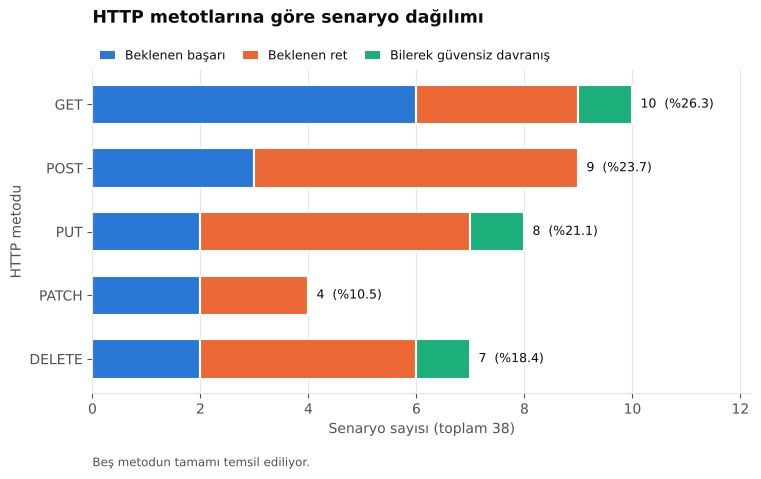

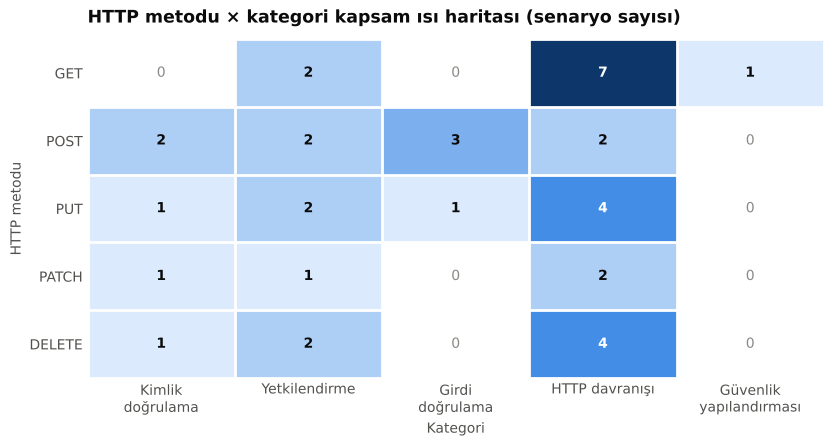

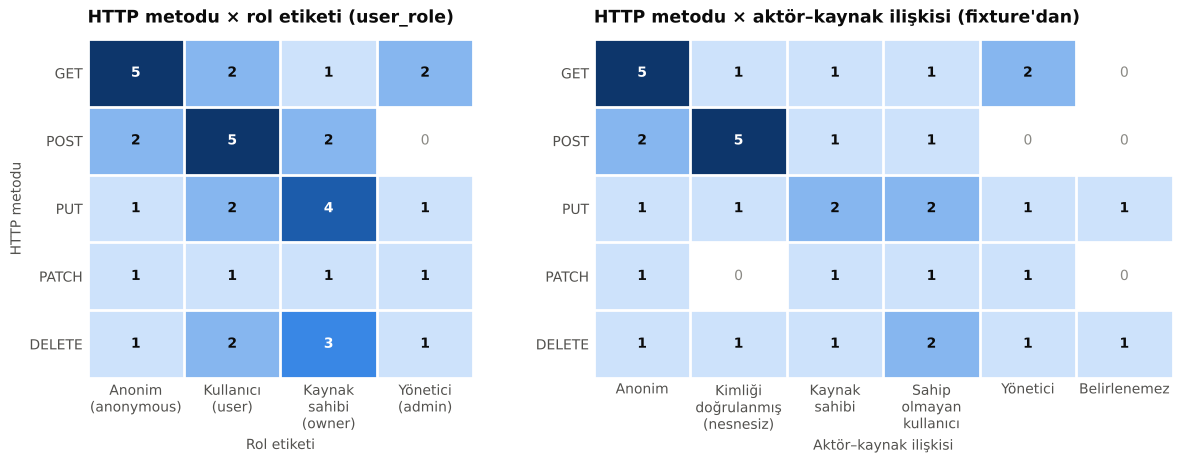

In [8]:
path, fig = plots.fig_methods(method_dist, FIG_DIR / "01_http_metot_dagilimi.png"); plt.show()
path, fig = plots.fig_method_category(tabs["metot_x_kategori"], FIG_DIR / "06_metot_kategori_isi_haritasi.png"); plt.show()
path, fig = plots.fig_method_role(tabs["metot_x_rol"], tabs["metot_x_aktor_iliskisi"],
                                  FIG_DIR / "07_metot_rol_isi_haritasi.png"); plt.show()

## 7. Kategori ve endpoint kapsamı

Kategoriler şemadaki `category` enum'undan okunur. Endpoint türleri `urls.py` rotalarından ve view
modülünden türetilir; view türü (ViewSet / APIView / Generic APIView) Django çözümlemesinden gelir.

,deger,gorunen_ad,senaryo_sayisi,yuzde,pozitif,negatif,beklenen_basari,beklenen_ret,bilerek_guvensiz,temsil_durumu
0,AUTHENTICATION,Kimlik doğrulama,5,13.2,0,5,0,5,0,Temsil ediliyor
1,AUTHORIZATION,Yetkilendirme,9,23.7,1,8,1,6,2,Temsil ediliyor
2,INPUT_VALIDATION,Girdi doğrulama,4,10.5,0,4,0,4,0,Temsil ediliyor
3,HTTP_BEHAVIOR,HTTP davranışı,19,50.0,14,5,14,5,0,Temsil ediliyor
4,SECURITY_CONFIGURATION,Güvenlik yapılandırması,1,2.6,0,1,0,0,1,Düşük temsil (eşik %10)


**Endpoint deseni dağılımı**

,endpoint_turu,endpoint_turu_ad,endpoint_deseni,view,view_turu,senaryo_sayisi,yuzde,metotlar,somut_endpointler
0,guvenli_koleksiyon,Güvenli koleksiyon,/api/articles/,catalog.views.ArticleViewSet,ViewSet,11,28.9,GET;POST;PUT;DELETE,/api/articles/
1,guvenli_nesne,Güvenli nesne (detay),/api/articles/<pk>/,catalog.views.ArticleViewSet,ViewSet,21,55.3,GET;PUT;PATCH;DELETE,/api/articles/1/;/api/articles/2/;/api/articles/3/;/api/articles/999/
2,guvenli_nesne_aksiyonu,Güvenli nesne aksiyonu,/api/articles/<int:pk>/publish/,catalog.views.ArticlePublishView,APIView,3,7.9,POST,/api/articles/2/publish/
3,guvensiz_koleksiyon,Bilerek güvensiz koleksiyon,/api/insecure/articles/,catalog.insecure.InsecureArticleList,Generic APIView,1,2.6,GET,/api/insecure/articles/
4,guvensiz_nesne,Bilerek güvensiz nesne (detay),/api/insecure/articles/<int:pk>/,catalog.insecure.InsecureArticleDetail,Generic APIView,2,5.3,PUT;DELETE,/api/insecure/articles/1/;/api/insecure/articles/3/


**Endpoint deseni × HTTP metodu**

http_method,GET,POST,PUT,PATCH,DELETE
endpoint_pattern,,,,,
/api/articles/,3,6,1,0,1
/api/articles/<int:pk>/publish/,0,3,0,0,0
/api/articles/<pk>/,6,0,6,4,5
/api/insecure/articles/,1,0,0,0,0
/api/insecure/articles/<int:pk>/,0,0,1,0,1


Güvenlikle ilişkili kategoriler: Kimlik doğrulama = 5, Yetkilendirme = 9, Girdi doğrulama = 4, Güvenlik yapılandırması = 1 (toplam 19/38). HTTP davranışı kategorisi = 19.

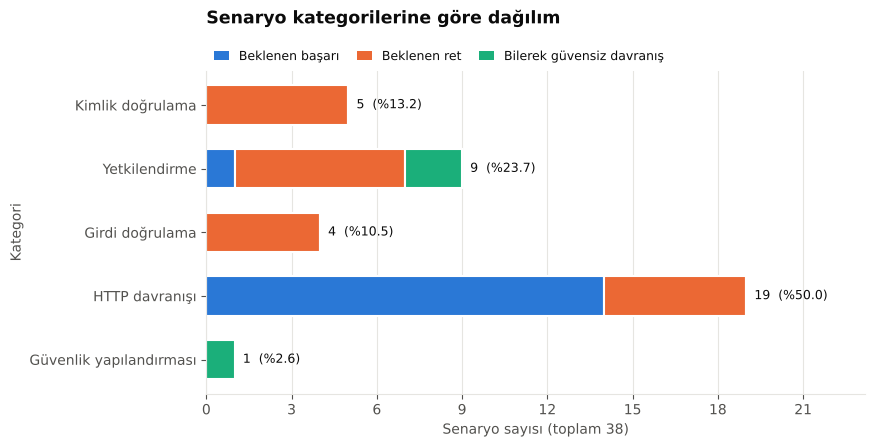

In [9]:
cat_dist = cov.category_distribution(df, ctx.schema)
display(cat_dist)
display(Markdown("**Endpoint deseni dağılımı**"))
display(cov.endpoint_distribution(df))
display(Markdown("**Endpoint deseni × HTTP metodu**"))
display(cov.crosstab(df, "endpoint_pattern", "http_method", None, list(HTTP_METHODS)))
sec = {c: int((df.category == c).sum()) for c in ("AUTHENTICATION", "AUTHORIZATION", "INPUT_VALIDATION",
                                                    "SECURITY_CONFIGURATION")}
display(Markdown("Güvenlikle ilişkili kategoriler: " + ", ".join(
    f"{cov.CATEGORY_LABELS[k]} = {v}" for k, v in sec.items()) +
    f" (toplam {sum(sec.values())}/{len(df)}). HTTP davranışı kategorisi = "
    f"{int((df.category == 'HTTP_BEHAVIOR').sum())}."))
path, fig = plots.fig_categories(cat_dist, FIG_DIR / "03_kategori_dagilimi.png"); plt.show()

## 8. Kullanıcı rolleri ve kimlik doğrulama

Üç boyut **birbirinden ayrı** ele alınır:

- `user_role`: veri kümesindeki etiket (`anonymous`, `user`, `owner`, `admin`).
- **Fixture kimliği:** `fixture_ref.user` (admin, alice, bob, carol). Kullanıcı adları izin sınıfı değildir.
- **Aktör–kaynak ilişkisi:** fixture verisinden türetilir — `is_staff` → yönetici; makale `owner`
  alanı → kaynak sahibi / sahip olmayan; makale referansı yoksa "kimliği doğrulanmış (nesnesiz)";
  hedef makale fixture'da yoksa "belirlenemez".

,boyut,deger,gorunen_ad,senaryo_sayisi,yuzde,pozitif,negatif,beklenen_basari,beklenen_ret,bilerek_guvensiz,temsil_durumu
0,user_role (etiket),anonymous,Anonim (anonymous),10,26.3,2,8,2,7,1,Temsil ediliyor
1,user_role (etiket),user,Kullanıcı (user),12,31.6,2,10,2,8,2,Temsil ediliyor
2,user_role (etiket),owner,Kaynak sahibi (owner),11,28.9,6,5,6,5,0,Temsil ediliyor
3,user_role (etiket),admin,Yönetici (admin),5,13.2,5,0,5,0,0,Temsil ediliyor
4,fixture kimliği,admin,admin,5,13.2,5,0,5,0,0,Temsil ediliyor
5,fixture kimliği,alice,alice,11,28.9,6,5,6,5,0,Temsil ediliyor
6,fixture kimliği,bob,bob,0,0.0,0,0,0,0,0,Temsil edilmiyor
7,fixture kimliği,carol,carol,12,31.6,2,10,2,8,2,Temsil ediliyor
8,fixture kimliği,(kimlik yok / anonim),(kimlik yok / anonim),10,26.3,2,8,2,7,1,Temsil ediliyor
9,aktör–kaynak ilişkisi (fixture'dan türetilmiş),anonim,Anonim,10,26.3,2,8,2,7,1,Temsil ediliyor


**user_role × fixture kimliği**

fixture_user,(anonim),admin,alice,carol
user_role,,,,
admin,0,5,0,0
anonymous,10,0,0,0
owner,0,0,11,0
user,0,0,0,12


**user_role × aktör–kaynak ilişkisi**

actor_relation,anonim,belirlenemez,kaynak_sahibi,kimligi_dogrulanmis,sahip_olmayan,yonetici
user_role,,,,,,
admin,0,0,0,0,0,5
anonymous,10,0,0,0,0,0
owner,0,2,6,3,0,0
user,0,0,0,5,7,0


**Fixture kullanıcıları** (izin semantiğinin kaynağı)

,pk,username,is_staff,sahip_olduğu_makaleler
0,1,admin,True,[]
1,2,alice,False,"[1, 2]"
2,3,bob,False,"[3, 4]"
3,4,carol,False,[]


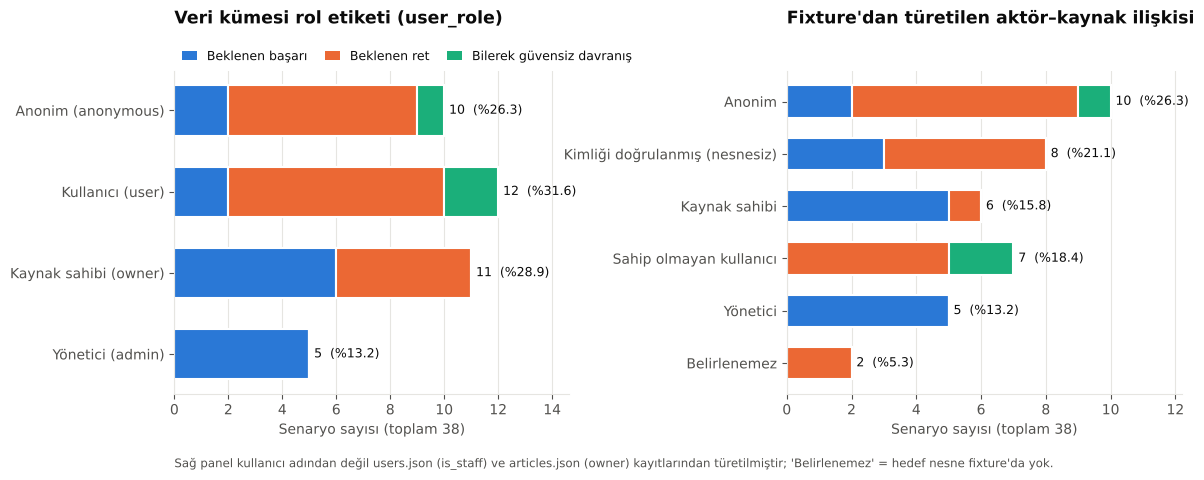

In [10]:
role_dist = cov.role_distribution(df, ctx.schema, ctx.users)
display(role_dist)
display(Markdown("**user_role × fixture kimliği**"))
display(cov.crosstab(df.assign(fixture_user=df.fixture_user.fillna("(anonim)")), "user_role", "fixture_user"))
display(Markdown("**user_role × aktör–kaynak ilişkisi**"))
display(cov.crosstab(df, "user_role", "actor_relation"))
display(Markdown("**Fixture kullanıcıları** (izin semantiğinin kaynağı)"))
display(pd.DataFrame([{"pk": u["pk"], "username": u["fields"]["username"], "is_staff": u["fields"]["is_staff"],
                       "sahip_olduğu_makaleler": [a["pk"] for a in ctx.articles if a["fields"]["owner"] == u["pk"]]}
                      for u in ctx.users]))
path, fig = plots.fig_roles(role_dist, FIG_DIR / "04_rol_dagilimi.png"); plt.show()

## 9. Yetkilendirme ve sahiplik kapsamı (PUT / PATCH / DELETE)

Kapsam modeli (`cov.COVERAGE_MODEL`), hedef uygulamanın alan modeline göre anlamlı hücreleri
açıkça listeler (kör Kartezyen çarpım değildir). Hücre durumları:

- **Açıkça mevcut:** hücreye eşlenen en az bir senaryo var.
- **Dolaylı temsil:** hücre boş, ancak kardeş metotta (PUT↔PATCH; DRF'te ortak `UpdateModelMixin.update`
  yolu) aynı koşul mevcut. Yine de açık senaryo önerilir.
- **Kapsanmıyor:** hücreye eşlenen kayıt yok.
- **Uygulanamaz:** koşul bu metotta anlamsız (ör. DELETE'te girdi doğrulama).
- **Yetersiz meta veri:** koşul belirlenemeyen kayıtlar bölüm 14'te ayrıca listelenir.

Kapsanmayan hücre bir **kapsam boşluğudur**; doğrulanmış güvenlik açığı anlamına gelmez.

,endpoint_turu_ad,http_metodu,kosul_ad,durum,oncelik,senaryo_idleri,beklenen_durum_kodlari,kaynak_gorunurlugu,dolayli_kanit
0,Güvenli nesne (detay),PUT,Anonim,Açıkça mevcut,Yüksek,SC-AUT-002,401,Yayında,
1,Güvenli nesne (detay),PUT,Kaynak sahibi,Açıkça mevcut,Yüksek,SC-UPD-001,200,Yayında,
2,Güvenli nesne (detay),PUT,Sahip olmayan kullanıcı,Açıkça mevcut,Yüksek,SC-AUZ-001,403,Yayında,
3,Güvenli nesne (detay),PUT,Yönetici,Açıkça mevcut,Yüksek,SC-UPD-002,200,Yayında,
4,Güvenli nesne (detay),PUT,Mevcut olmayan kaynak,Açıkça mevcut,Yüksek,SC-NF-001,404,Mevcut değil,
5,Güvenli nesne (detay),PUT,Geçersiz girdi,Açıkça mevcut,Yüksek,SC-INP-003,400,Yayında,
6,Güvenli nesne (detay),PATCH,Anonim,Açıkça mevcut,Yüksek,SC-AUT-003,401,Yayında,
7,Güvenli nesne (detay),PATCH,Kaynak sahibi,Açıkça mevcut,Yüksek,SC-UPD-003,200,Yayında,
8,Güvenli nesne (detay),PATCH,Sahip olmayan kullanıcı,Açıkça mevcut,Yüksek,SC-AUZ-002,403,Yayında,
9,Güvenli nesne (detay),PATCH,Yönetici,Açıkça mevcut,Yüksek,SC-UPD-004,200,Yayında,


**Durum sayıları (PUT/PATCH/DELETE, nesne uçları):**

,endpoint_turu_ad,durum,hücre
0,Bilerek güvensiz nesne (detay),Açıkça mevcut,2
1,Bilerek güvensiz nesne (detay),Dolaylı temsil,1
2,Bilerek güvensiz nesne (detay),Kapsanmıyor,3
3,Güvenli nesne (detay),Açıkça mevcut,15
4,Güvenli nesne (detay),Dolaylı temsil,2
5,Güvenli nesne (detay),Uygulanamaz,1


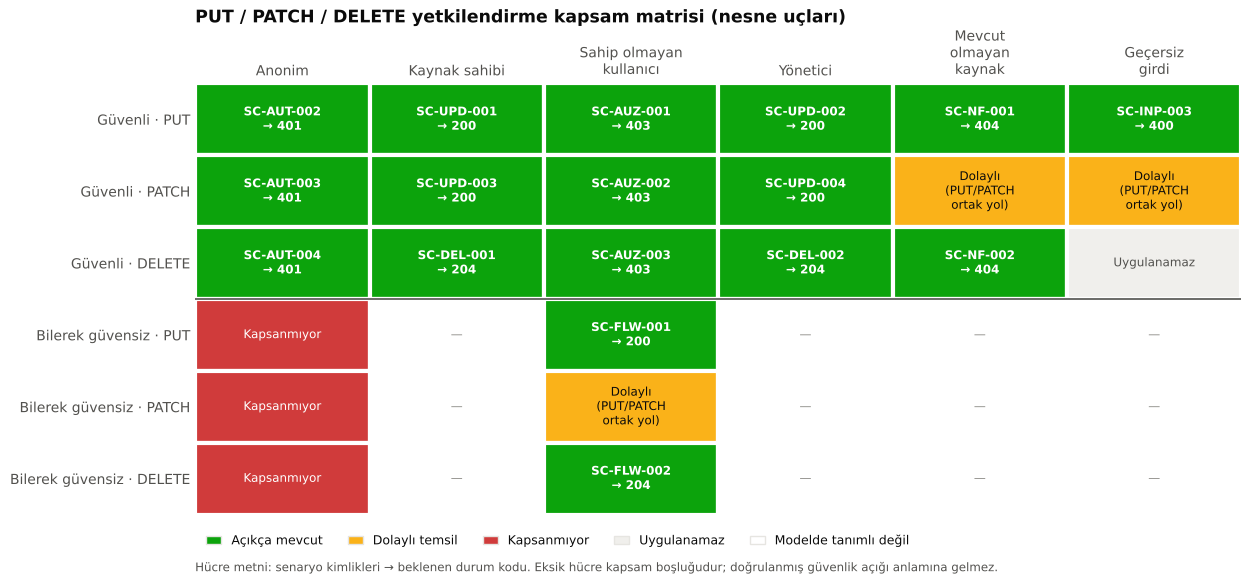

In [11]:
matrix = cov.coverage_matrix(df)
authz = cov.authorization_coverage(matrix)
display(authz[["endpoint_turu_ad", "http_metodu", "kosul_ad", "durum", "oncelik", "senaryo_idleri",
               "beklenen_durum_kodlari", "kaynak_gorunurlugu", "dolayli_kanit"]])
display(Markdown("**Durum sayıları (PUT/PATCH/DELETE, nesne uçları):**"))
display(authz.groupby(["endpoint_turu_ad", "durum"]).size().rename("hücre").reset_index())
path, fig = plots.fig_authorization(authz, FIG_DIR / "08_put_patch_delete_yetkilendirme_kapsami.png"); plt.show()

## 10. Beklenen HTTP durum kodları

Durum kodlarının tutarlılığı **evrensel HTTP varsayımlarıyla değerlendirilmez** (her DELETE → 204,
her yetkisiz istek → 401 gibi). Kullanılan kanıtlar:

1. **Django URL çözümlemesi:** view'ın metodu desteklemediği durumda 405 beklenmesi (kesin kural).
2. **Hedef uygulama yapılandırması:** `BasicAuthentication` etkin olduğundan kimlik doğrulanmamış
   isteğe DRF'in 401 döndürmesi; `is_staff` yöneticinin nesne izinlerini geçmesi. Bunlara aykırı
   kayıtlar yalnızca **"inceleme"** olarak raporlanır.
3. Gerçek davranış eşleşmesi H3-01 `pytest` senaryo↔uygulama testinin kapsamındadır (bu notebook
   HTTP isteği çalıştırmaz).

,deger,gorunen_ad,senaryo_sayisi,yuzde,pozitif,negatif,beklenen_basari,beklenen_ret,bilerek_guvensiz,temsil_durumu
0,200,200,13,34.2,11,2,11,0,2,Temsil ediliyor
1,201,201,2,5.3,2,0,2,0,0,Düşük temsil (eşik %10)
2,204,204,3,7.9,2,1,2,0,1,Düşük temsil (eşik %10)
3,400,400,4,10.5,0,4,0,4,0,Temsil ediliyor
4,401,401,5,13.2,0,5,0,5,0,Temsil ediliyor
5,403,403,4,10.5,0,4,0,4,0,Temsil ediliyor
6,404,404,5,13.2,0,5,0,5,0,Temsil ediliyor
7,405,405,2,5.3,0,2,0,2,0,Düşük temsil (eşik %10)


**durum_kodu_x_rol**

user_role,anonymous,user,owner,admin
expected_http_status,,,,
200,3,2,4,4
201,0,1,1,0
204,0,1,1,1
400,0,3,1,0
401,5,0,0,0
403,0,4,0,0
404,2,1,2,0
405,0,0,2,0


**durum_kodu_x_aktor_iliskisi**

actor_relation,anonim,kimligi_dogrulanmis,kaynak_sahibi,sahip_olmayan,yonetici,belirlenemez
expected_http_status,,,,,,
200,3,1,4,1,4,0
201,0,2,0,0,0,0
204,0,0,1,1,1,0
400,0,3,1,0,0,0
401,5,0,0,0,0,0
403,0,0,0,4,0,0
404,2,0,0,1,0,2
405,0,2,0,0,0,0


**durum_kodu_x_kategori**

category,AUTHENTICATION,AUTHORIZATION,INPUT_VALIDATION,HTTP_BEHAVIOR,SECURITY_CONFIGURATION
expected_http_status,,,,,
200,0,2,0,10,1
201,0,0,0,2,0
204,0,1,0,2,0
400,0,0,4,0,0
401,5,0,0,0,0
403,0,4,0,0,0
404,0,2,0,3,0
405,0,0,0,2,0


**Django URL çözümlemesi: endpoint → view ve desteklenen metotlar**

,endpoint,allowed_methods,url_name,view,view_type
0,/api/articles/,"GET, POST",article-list,catalog.views.ArticleViewSet,ViewSet
1,/api/articles/1/,"DELETE, GET, PATCH, PUT",article-detail,catalog.views.ArticleViewSet,ViewSet
2,/api/articles/2/,"DELETE, GET, PATCH, PUT",article-detail,catalog.views.ArticleViewSet,ViewSet
3,/api/articles/2/publish/,POST,article-publish,catalog.views.ArticlePublishView,APIView
4,/api/articles/3/,"DELETE, GET, PATCH, PUT",article-detail,catalog.views.ArticleViewSet,ViewSet
5,/api/articles/999/,"DELETE, GET, PATCH, PUT",article-detail,catalog.views.ArticleViewSet,ViewSet
6,/api/insecure/articles/,GET,insecure-article-list,catalog.insecure.InsecureArticleList,Generic APIView
7,/api/insecure/articles/1/,"DELETE, GET, PATCH, PUT",insecure-article-detail,catalog.insecure.InsecureArticleDetail,Generic APIView
8,/api/insecure/articles/3/,"DELETE, GET, PATCH, PUT",insecure-article-detail,catalog.insecure.InsecureArticleDetail,Generic APIView


Durum kodu tutarsızlığı / inceleme kaydı: 0


,bulgu_no,konum,senaryo_id,alan,sorun_turu,onem_derecesi,kontrol_katmani,aciklama,kanit,onerilen_duzeltme


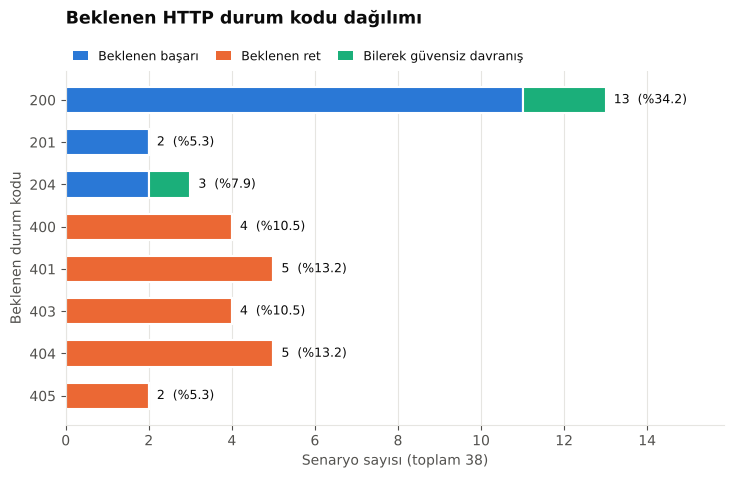

In [12]:
status_dist = cov.status_distribution(df, ctx.schema)
display(status_dist)
for name in ("durum_kodu_x_rol", "durum_kodu_x_aktor_iliskisi", "durum_kodu_x_kategori"):
    display(Markdown(f"**{name}**")); display(tabs[name])
if ctx.method_support:
    display(Markdown("**Django URL çözümlemesi: endpoint → view ve desteklenen metotlar**"))
    display(pd.DataFrame([{"endpoint": k, **v, "allowed_methods": ", ".join(v["allowed_methods"])}
                          for k, v in sorted(ctx.method_support.items())]))
status_findings = q.findings_frame(q.check_method_support(ctx.scenarios, ctx.method_support)
                                   + q.check_status_plausibility(ctx.scenarios))
print(f"Durum kodu tutarsızlığı / inceleme kaydı: {len(status_findings)}")
display(status_findings)
path, fig = plots.fig_status(status_dist, FIG_DIR / "05_durum_kodu_dagilimi.png"); plt.show()

## 11. Pozitif ve negatif senaryolar

H3-01 README'si ve kayıtların kendisi incelendiğinde etiketlerin anlamı şöyledir:

- `positive`: güvenli uçta beklenen **başarılı** davranış (2xx).
- `negative`: beklenen **ret** (4xx) **veya** bilerek güvensiz uçta gözlemlenen hatalı davranış
  (`is_intentional_flaw: true`, gözlemlenen kod 2xx olabilir).

"Negatif" bozuk veri veya başarısız test anlamına gelmez. Bu yorumla uyuşmayan kayıtlar
"Tutarsız / doğrulanamayan" sınıfına düşer ve veri kalitesi bulgusu olarak raporlanır.

,deger,gorunen_ad,senaryo_sayisi,yuzde,pozitif,negatif,beklenen_basari,beklenen_ret,bilerek_guvensiz,temsil_durumu,boyut
0,positive,Pozitif,15,39.5,15,0,15,0,0,Temsil ediliyor,label
1,negative,Negatif,23,60.5,0,23,0,20,3,Temsil ediliyor,label
2,Beklenen başarı,Beklenen başarı,15,39.5,15,0,15,0,0,Temsil ediliyor,beklenti sınıfı (türetilmiş)
3,Beklenen ret,Beklenen ret,20,52.6,0,20,0,20,0,Temsil ediliyor,beklenti sınıfı (türetilmiş)
4,Bilerek güvensiz davranış,Bilerek güvensiz davranış,3,7.9,0,3,0,0,3,Düşük temsil (eşik %10),beklenti sınıfı (türetilmiş)
5,Tutarsız / doğrulanamayan,Tutarsız / doğrulanamayan,0,0.0,0,0,0,0,0,Temsil edilmiyor,beklenti sınıfı (türetilmiş)


expectation_class,Beklenen başarı,Beklenen ret,Bilerek güvensiz davranış
label,,,
negative,0,20,3
positive,15,0,0


**Kategori × beklenti sınıfı**

expectation_class,Beklenen başarı,Beklenen ret,Bilerek güvensiz davranış,Tutarsız / doğrulanamayan
category,,,,
AUTHENTICATION,0,5,0,0
AUTHORIZATION,1,6,2,0
INPUT_VALIDATION,0,4,0,0
HTTP_BEHAVIOR,14,5,0,0
SECURITY_CONFIGURATION,0,0,1,0


Etiket tutarsızlığı: 0; tutarsız sınıftaki kayıt: 0


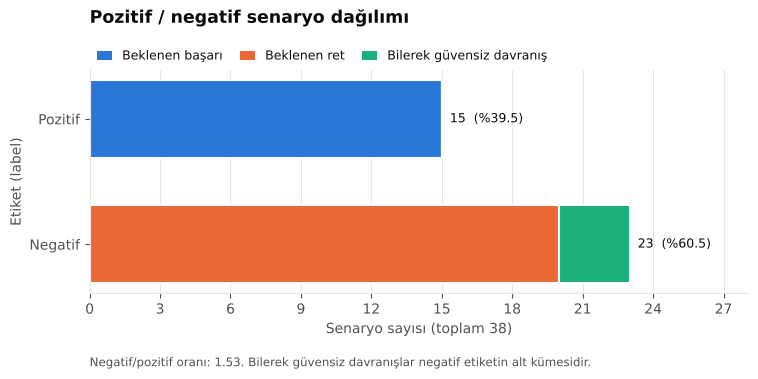

In [13]:
class_dist = pd.concat([cov.label_distribution(df).assign(boyut="label"),
                        cov.expectation_distribution(df).assign(boyut="beklenti sınıfı (türetilmiş)")],
                       ignore_index=True)
display(class_dist)
display(cov.crosstab(df, "label", "expectation_class"))
display(Markdown("**Kategori × beklenti sınıfı**")); display(tabs["kategori_x_beklenti_sinifi"])
label_findings = q.findings_frame(q.check_label_consistency(ctx.scenarios))
print(f"Etiket tutarsızlığı: {len(label_findings)}; tutarsız sınıftaki kayıt: "
      f"{int((df.expectation_class == 'Tutarsız / doğrulanamayan').sum())}")
path, fig = plots.fig_classes(class_dist, FIG_DIR / "02_pozitif_negatif_dagilimi.png"); plt.show()

## 12. Bilerek eklenen güvenlik hataları

Bilerek-hatalı senaryolar **veri hatası değildir**; güvenlik tespitinin değerlendirilmesi için
kasıtlı olarak eklenmiştir. Aşağıda her biri, güvenli uçtaki karşılığıyla (aynı metot, uç şekli ve
aktör ilişkisi) eşlenir ve zafiyet iddiası kaynak kodla (`catalog/insecure.py`) desteklenir.

In [14]:
flaws = cov.intentional_flaws(df, ctx.scenarios)
display(flaws)
src = (ctx.paths.sample_app / "catalog" / "insecure.py").read_text(encoding="utf-8").splitlines()
print("Kaynak kanıtı — catalog/insecure.py (sınıf tanımları ve BUG işaretleri):")
for i, line in enumerate(src, 1):
    if line.startswith("class ") or "BUG" in line or "permission_classes" in line or "queryset" in line:
        print(f"{i:>4}: {line}")

,senaryo_id,http_metodu,endpoint,view,kategori,user_role,fixture_kimligi,aktor_iliskisi,gozlemlenen_durum_kodu,label,flaw_explanation,guvenli_karsilik_idleri,guvenli_karsilik_durum_kodlari,aciklamadaki_guvenli_kod,aciklama_karsilik_uyumu
0,SC-FLW-001,PUT,/api/insecure/articles/1/,catalog.insecure.InsecureArticleDetail,AUTHORIZATION,user,carol,sahip_olmayan,200,negative,BOLA/IDOR (OWASP API1:2023): nesne düzeyi sahiplik kontrolü yok. Güvenli uçta beklenen...,SC-AUZ-001,403,403,Uyumlu
1,SC-FLW-002,DELETE,/api/insecure/articles/3/,catalog.insecure.InsecureArticleDetail,AUTHORIZATION,user,carol,sahip_olmayan,204,negative,BOLA/IDOR: sahip olmayan kullanıcı silebiliyor. Güvenli uçta beklenen 403.,SC-AUZ-003,403,403,Uyumlu
2,SC-FLW-003,GET,/api/insecure/articles/,catalog.insecure.InsecureArticleList,SECURITY_CONFIGURATION,anonymous,NaN,anonim,200,negative,AllowAny + filtrelemesiz queryset: hassas veri ifşası. Güvenli listede taslaklar gizli...,SC-LST-001,200,,Açıklamada kod yok


Kaynak kanıtı — catalog/insecure.py (sınıf tanımları ve BUG işaretleri):
  11:   2) InsecureArticleList — AllowAny + filtrelemesiz queryset. Yayınlanmamış (taslak)
  21: class InsecureArticleDetail(generics.RetrieveUpdateDestroyAPIView):
  22:     # BUG: Nesne düzeyi sahiplik kontrolü yok. Güvenli muadili ownership ister.
  23:     queryset = Article.objects.all()
  25:     permission_classes = [IsAuthenticated]
  28: class InsecureArticleList(generics.ListAPIView):
  29:     # BUG: Tüm kayıtları (taslaklar dâhil) herkese döndürür.
  30:     queryset = Article.objects.all()
  32:     permission_classes = [AllowAny]


## 13. Veri kalitesi doğrulaması

Tüm kontroller `scenario_eda.quality` içinde saf ve test edilebilir fonksiyonlardır
(`tests/test_quality_checks.py`). Her bulgu: konum, senaryo kimliği (yoksa `scenarios[<sıra>]`),
alan, sorun türü, önem derecesi, kontrol katmanı, açıklama, kanıt ve önerilen düzeltme içerir.
**Bilgi** düzeyindeki kayıtlar hata değil, belgelenmesi önerilen meta veri gözlemleridir.

,kontrol,kontrol_katmani,durum,incelenen_kayit,bulgu_sayisi
0,JSON Schema doğrulaması (Draft 2020-12),JSON Schema,Çalıştırıldı,38,0
1,"Eksik/null zorunlu alan, boş metin, geçersiz enum/tip, kimlik biçimi, hata açıklaması",Semantik,Çalıştırıldı,38,0
2,Yinelenen senaryo kimliği,Semantik,Çalıştırıldı,38,0
3,Aynı isteği tanımlayan yinelenen içerik,Semantik,Çalıştırıldı,38,0
4,Pozitif/negatif etiket – durum kodu – bilerek-hata tutarlılığı,Semantik,Çalıştırıldı,38,0
5,"Fixture kullanıcı/makale, rol semantiği, endpoint çözümleme, güvensiz uç işareti",Referans bütünlüğü (statik),Çalıştırıldı,38,5
6,View metot desteği ile 405 beklentisi,Django URL çözümlemesi,Çalıştırıldı,38,0
7,Durum kodu makullüğü (proje-özgü sezgisel kurallar),Durum kodu incelemesi (sezgisel),Çalıştırıldı,38,0
8,Türetilmiş CSV ↔ kanonik JSON hücre karşılaştırması,JSON/CSV tutarlılığı,Çalıştırıldı,38,0


,kontrol_katmani,onem_derecesi,bulgu_sayisi
0,Referans bütünlüğü (statik),Bilgi,5


,bulgu_no,konum,senaryo_id,alan,sorun_turu,onem_derecesi,kontrol_katmani,aciklama,kanit,onerilen_duzeltme
0,DQ-001,scenarios[15],SC-CRT-002,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,koleksiyon ucu (nesne yok); user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
1,DQ-002,scenarios[30],SC-NF-001,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,makale 999 fixture'da yok; user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
2,DQ-003,scenarios[31],SC-NF-002,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,makale 999 fixture'da yok; user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
3,DQ-004,scenarios[32],SC-MNA-001,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,koleksiyon ucu (nesne yok); user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
4,DQ-005,scenarios[33],SC-MNA-002,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,koleksiyon ucu (nesne yok); user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...


**Doğrulanmış veri hatası (Kritik/Yüksek/Orta/Düşük): 0** · Bilgi: 5

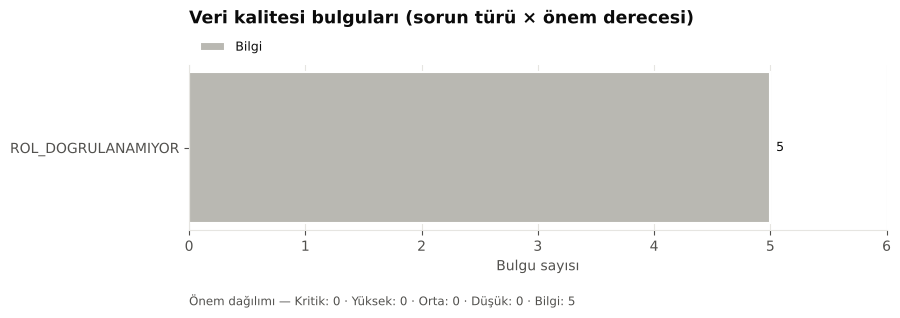

In [15]:
findings, inventory = q.run_checks(ctx)
display(inventory)
display(q.check_summary(findings))
display(findings)
sev = findings["onem_derecesi"].value_counts().to_dict() if len(findings) else {}
verified = sum(sev.get(s, 0) for s in ("Kritik", "Yüksek", "Orta", "Düşük"))
display(Markdown(f"**Doğrulanmış veri hatası (Kritik/Yüksek/Orta/Düşük): {verified}** · Bilgi: {sev.get('Bilgi', 0)}"))
path, fig = plots.fig_findings(findings, FIG_DIR / "09_veri_kalitesi_bulgulari.png"); plt.show()

## 14. Fixture referans bütünlüğü

Yapılan **statik** kontroller: `fixture_ref.user` → `users.json`; `fixture_ref.article` →
`articles.json` (404 beklenen kayıtlarda kasıtlı olarak mevcut olmayan kaynak kabul edilir);
endpoint → `urls.py` rota deseni; endpoint'teki `pk` ↔ `fixture_ref.article`; rol etiketi ↔
fixture'daki `is_staff`/`owner`; güvensiz uç ↔ `is_intentional_flaw`.

**Sınır:** Bu kontroller fixture'ların veritabanına yüklendiğini veya isteklerin beklenen kodu
ürettiğini kanıtlamaz; bu davranışsal doğrulama H3-01 `pytest` paketinde yapılır.

In [16]:
ref = findings[findings.kontrol_katmani.isin([q.LAYER_REFERENCE, q.LAYER_DJANGO])]
display(ref)
ref_stats = pd.DataFrame([
    {"kontrol": "fixture_ref.user çözümlendi", "sayı": int(df.fixture_user.dropna().isin(
        {u["fields"]["username"] for u in ctx.users}).sum()), "toplam": int(df.fixture_user.notna().sum())},
    {"kontrol": "fixture_ref.article mevcut", "sayı": int(df.resource_state.isin(["Yayında", "Taslak"]).sum()),
     "toplam": int(df.fixture_article.notna().sum())},
    {"kontrol": "fixture_ref.article bilerek mevcut değil (404)", "sayı": int((df.resource_state == "Mevcut değil").sum()),
     "toplam": int(df.fixture_article.notna().sum())},
    {"kontrol": "endpoint statik rotaya çözümlendi", "sayı": int(df.endpoint_pattern.notna().sum()), "toplam": len(df)},
    {"kontrol": "endpoint Django ile çözümlendi", "sayı": int(df.view_type.notna().sum()), "toplam": len(df)},
])
ref_stats

,bulgu_no,konum,senaryo_id,alan,sorun_turu,onem_derecesi,kontrol_katmani,aciklama,kanit,onerilen_duzeltme
0,DQ-001,scenarios[15],SC-CRT-002,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,koleksiyon ucu (nesne yok); user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
1,DQ-002,scenarios[30],SC-NF-001,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,makale 999 fixture'da yok; user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
2,DQ-003,scenarios[31],SC-NF-002,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,makale 999 fixture'da yok; user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
3,DQ-004,scenarios[32],SC-MNA-001,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,koleksiyon ucu (nesne yok); user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...
4,DQ-005,scenarios[33],SC-MNA-002,user_role,ROL_DOGRULANAMIYOR,Bilgi,Referans bütünlüğü (statik),owner rolü fixture verisinden doğrulanamıyor; istek hedefinde sahibi belirlenebilecek ...,koleksiyon ucu (nesne yok); user=alice,Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senar...


,kontrol,sayı,toplam
0,fixture_ref.user çözümlendi,28,28
1,fixture_ref.article mevcut,23,26
2,fixture_ref.article bilerek mevcut değil (404),3,26
3,endpoint statik rotaya çözümlendi,38,38
4,endpoint Django ile çözümlendi,38,38


## 15. PyGoat ve kontrollü fixture kaynakları

`benchmarks/pygoat/` dizini envanterlenir; JSON/CSV/YAML senaryo dosyası olup olmadığı ve kayıt
sayısı hesaplanır. PyGoat kaydı yoksa nicel karşılaştırma yapılmaz ve kaynak karşılaştırma grafiği
**üretilmez** (sıfır çubuklu yanıltıcı bir grafik yerine).

In [17]:
display(pd.DataFrame([ctx.pygoat]))
source_cmp = cov.source_comparison(df, ctx.pygoat, ctx.data)
display(source_cmp)
if ctx.pygoat["scenario_records"] == 0:
    display(Markdown(
        "Depoda **PyGoat senaryo kaydı yok** (yalnızca `" + "`, `".join(ctx.pygoat["files"]) + "`). "
        "Bu nedenle kaynaklar arası nicel karşılaştırma yapılamaz ve grafik üretilmedi. Bu durum kontrollü "
        "fixture veri kümesinin kusuru değildir; PyGoat sürüm sabitleme ve ground truth H3-03 kapsamındadır."))

,dir_exists,files,data_files,scenario_records,has_readme
0,True,[README.md],[],0,True


,kaynak,depo_konumu,veri_kumesi,senaryo_kaydi,http_metodu,kategori,pozitif,negatif,bilerek_hatali,degerlendirme_hazirligi
0,Kontrollü Django/DRF fixture,benchmarks/drf_fixtures/scenarios/scenarios.json,h3-01-drf-controlled v1.0.0,38,5,5,15,23,3,"Etiketli, şema ile doğrulanmış; H3-01 senaryo↔uygulama testleriyle eşlenmiş."
1,PyGoat,benchmarks/pygoat/,—,0,<NA>,<NA>,<NA>,<NA>,<NA>,Etiketli senaryo kaydı yok; dizinde yalnızca inceleme/planlama notu var (README.md). N...


Depoda **PyGoat senaryo kaydı yok** (yalnızca `README.md`). Bu nedenle kaynaklar arası nicel karşılaştırma yapılamaz ve grafik üretilmedi. Bu durum kontrollü fixture veri kümesinin kusuru değildir; PyGoat sürüm sabitleme ve ground truth H3-03 kapsamındadır.

## 16. Kapsam boşluğu değerlendirmesi

Boşluklar dört sınıfta raporlanır: **Doğrulanmış eksik** (yüksek öncelikli hücrede kayıt yok),
**Olası eksik** (düşük/orta öncelikli veya dolaylı temsil edilen hücre, aktör/kimlik çeşitliliği),
**Uygulanamaz** (rapora boşluk olarak girmez) ve **Yetersiz meta veri**. Öneriler önceliğe göre
sıralıdır; önerilen yeni senaryoların beklenen kodları eklenmeden önce H3-01 testleriyle
doğrulanmalıdır.

durum,Açıkça mevcut,Dolaylı temsil,Kapsanmıyor,Uygulanamaz
endpoint_turu_ad,,,,
Bilerek güvensiz koleksiyon,1,0,0,0
Bilerek güvensiz nesne (detay),2,1,4,0
Güvenli koleksiyon,8,0,2,1
Güvenli nesne (detay),20,2,1,2
Güvenli nesne aksiyonu,3,0,3,1


,bosluk_no,siniflandirma,oncelik,kapsam_boyutu,endpoint_turu,http_metodu,kosul,aciklama,kanit,oneri
0,GAP-001,Olası eksik,Yüksek,endpoint türü × metot × koşul,guvenli_nesne,PATCH,kaynak_yok,Güvenli nesne (detay) / PATCH / Mevcut olmayan kaynak: dolaylı temsil. Güncelleme: kim...,PUT için SC-NF-001 mevcut; DRF'te PUT ve PATCH aynı UpdateModelMixin.update yolunu (pa...,Mevcut olmayan kaynak (ör. /api/articles/999/) için PATCH senaryosu ekleyin; beklenen ...
1,GAP-002,Olası eksik,Yüksek,endpoint türü × metot × koşul,guvenli_nesne,PATCH,gecersiz_girdi,Güvenli nesne (detay) / PATCH / Geçersiz girdi: dolaylı temsil. Güncelleme: kimlik doğ...,PUT için SC-INP-003 mevcut; DRF'te PUT ve PATCH aynı UpdateModelMixin.update yolunu (p...,Kaynak sahibi tarafından geçersiz girdiyle PATCH senaryosu ekleyin (ör. boş başlık); k...
2,GAP-003,Olası eksik,Yüksek,endpoint türü × metot × koşul,guvensiz_nesne,PATCH,sahip_olmayan,Bilerek güvensiz nesne (detay) / PATCH / Sahip olmayan kullanıcı: dolaylı temsil. BOLA...,PUT için SC-FLW-001 mevcut; DRF'te PUT ve PATCH aynı UpdateModelMixin.update yolunu (p...,Bilerek güvensiz uçta sahip olmayan kullanıcı ile PATCH (BOLA/IDOR) senaryosu ekleyin ...
3,GAP-004,Olası eksik,Orta,endpoint türü × metot × koşul,guvenli_nesne_aksiyonu,POST,yonetici,Güvenli nesne aksiyonu / POST / Yönetici: kapsanmıyor. Yayınlama: IsAuthenticated + sa...,"Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok.",Güvenli nesne aksiyonu ucunda POST için 'Yönetici' koşulunu temsil eden bir senaryo ek...
4,GAP-005,Olası eksik,Orta,endpoint türü × metot × koşul,guvensiz_nesne,GET,sahip_olmayan,Bilerek güvensiz nesne (detay) / GET / Sahip olmayan kullanıcı: kapsanmıyor. InsecureA...,"Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok.",Bilerek güvensiz detay ucunda sahip olmayan kullanıcının başkasının taslak kaydını oku...
5,GAP-006,Olası eksik,Orta,kategori × beklenti sınıfı,,,SECURITY_CONFIGURATION,'Güvenlik yapılandırması' kategorisindeki tüm kayıtlar bilerek-hatalı; güvenli uçta be...,SC-FLW-003,Bu kategoride güvenli uç için bir pozitif/kontrol senaryosu ekleyin (ör. güvenli liste...
6,GAP-007,Olası eksik,Orta,fixture kimliği,,,bob,Fixture kullanıcısı 'bob' kaynak sahibi olduğu halde hiçbir senaryoda istek yapan kiml...,"istek yapan kimlikler=['admin', 'alice', 'carol']",'bob' ile sahipler arası çapraz erişim senaryosu ekleyin (ör. bir kaynak sahibinin baş...
7,GAP-008,Olası eksik,Orta,aktör çeşitliliği,guvenli_nesne,PUT;PATCH;DELETE,sahip_olmayan,Güvenli nesne ucundaki tüm sahip-olmayan değiştirme senaryoları tek fixture kimliğiyle...,SC-AUZ-001;SC-AUZ-002;SC-AUZ-003,"Başka kayıtların sahibi olan bir kullanıcıyla (fixture'daki sahipler: alice, bob) başk..."
8,GAP-009,Olası eksik,Orta,kaynak görünürlüğü,guvenli_nesne,PUT;PATCH;DELETE,sahip_olmayan,Sahip olmayan kullanıcının başkasının TASLAK kaydını değiştirme girişimi temsil edilmi...,mevcut sahip-olmayan değiştirme senaryolarının kaynak durumu=['Yayında'],Taslak kayıt (ör. makale 2 veya 4) üzerinde sahip-olmayan PUT/PATCH/DELETE senaryosu e...
9,GAP-010,Olası eksik,Düşük,endpoint türü × metot × koşul,guvenli_koleksiyon,POST,yonetici,Güvenli koleksiyon / POST / Yönetici: kapsanmıyor. Yönetici oluşturma davranışı kimliğ...,"Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok.",Güvenli koleksiyon ucunda POST için 'Yönetici' koşulunu temsil eden bir senaryo ekleme...


Modelde karşılığı olmayan senaryo: 0


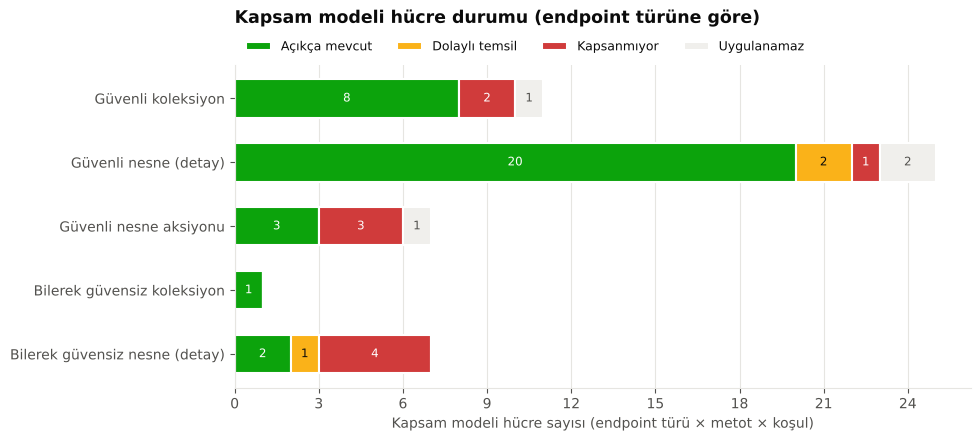

In [18]:
display(matrix.groupby(["endpoint_turu_ad", "durum"]).size().unstack(fill_value=0))
gaps = cov.coverage_gaps(df, matrix, ctx.schema, ctx.users, ctx.articles, ctx.data)
display(gaps)
print("Modelde karşılığı olmayan senaryo:", len(cov.unmodelled_scenarios(df)))
path, fig = plots.fig_coverage_cells(matrix, FIG_DIR / "10_kapsam_modeli_hucre_durumu.png"); plt.show()

## 17. Raporların dışa aktarımı

Tüm tablolar `reports/` altına CSV, özet `reports/eda_summary.md` olarak; tüm grafikler
`figures/` altına PNG (200 dpi) olarak yazılır. Çıktılar deterministiktir;
`tests/test_real_dataset.py` depodaki raporların bu notebook'un ürettikleriyle aynı olduğunu doğrular.

In [19]:
tables = report.build_report_tables(ctx)
written = report.export_reports(ctx, tables, REPORT_DIR)
figs = plots.render_all(ctx, tables, FIG_DIR)
pd.DataFrame([{"dosya": str(p.relative_to(REPO_ROOT)), "boyut_bayt": p.stat().st_size}
              for p in [*written, *figs.values()]])

,dosya,boyut_bayt
0,experiments/h3_02_eda/reports/general_statistics.csv,674
1,experiments/h3_02_eda/reports/method_distribution.csv,332
2,experiments/h3_02_eda/reports/class_distribution.csv,699
3,experiments/h3_02_eda/reports/category_distribution.csv,471
4,experiments/h3_02_eda/reports/role_distribution.csv,1489
5,experiments/h3_02_eda/reports/status_code_distribution.csv,478
6,experiments/h3_02_eda/reports/endpoint_distribution.csv,957
7,experiments/h3_02_eda/reports/cross_tabulations.csv,12658
8,experiments/h3_02_eda/reports/coverage_matrix.csv,11147
9,experiments/h3_02_eda/reports/authorization_coverage.csv,5754


In [20]:
# Doğrulama: rapor tabloları notebook boyunca hesaplanan değerlerle aynı olmalı.
assert list(tables["method_distribution"]["deger"]) == list(HTTP_METHODS)
assert tables["method_distribution"]["senaryo_sayisi"].sum() == len(df) == len(ctx.scenarios)
assert tables["data_quality_findings"].equals(findings)
assert tables["coverage_gaps"].equals(gaps)
assert set(tables["authorization_coverage"]["http_metodu"]) == set(MUTATING_METHODS)
assert set(tables["intentional_flaws"]["senaryo_id"]) == {s["id"] for s in ctx.scenarios if s.get("is_intentional_flaw")}
assert set(df["source"]) == {"Kontrollü Django/DRF fixture"}
print("Tüm tutarlılık doğrulamaları geçti.")
if IN_COLAB:
    print("Colab'da çıktıları indirmek için bir sonraki hücreyi çalıştırın.")

Tüm tutarlılık doğrulamaları geçti.


In [21]:
# Yeniden üretilen çıktıların depodaki (commit edilmiş) sürümle karşılaştırılması.
rel_reports = str(REPORT_DIR.relative_to(REPO_ROOT))
rel_figs = str(FIG_DIR.relative_to(REPO_ROOT))
changed_reports = git_info("status", "--porcelain", "--", rel_reports)
changed_figs = git_info("status", "--porcelain", "--", rel_figs)
if changed_reports is None:
    print("Git bilgisi yok: karşılaştırma yapılamadı (depo git ile alınmamış olabilir).")
else:
    print("Raporlar (CSV + eda_summary.md):",
          "depodaki sürümle BİREBİR AYNI" if not changed_reports else "FARKLI:\n" + changed_reports)
    print("Grafikler (PNG):",
          "depodaki sürümle birebir aynı" if not changed_figs else
          "piksel/bayt düzeyinde farklı (matplotlib/font sürümüne bağlı olabilir; içerik görsel olarak "
          "incelenmeli):\n" + changed_figs)

Raporlar (CSV + eda_summary.md): depodaki sürümle BİREBİR AYNI
Grafikler (PNG): depodaki sürümle birebir aynı


In [22]:
# Yalnızca Google Colab: raporları ve grafikleri ZIP olarak indirir (yerelde bir şey yapmaz).
if IN_COLAB:
    import zipfile
    from google.colab import files
    archive = Path("/content/h3_02_eda_ciktilari.zip")
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as zf:
        for folder in (REPORT_DIR, FIG_DIR):
            for f in sorted(folder.iterdir()):
                if f.is_file():
                    zf.write(f, f"{folder.name}/{f.name}")
    print(f"{archive} hazır: {len(zipfile.ZipFile(archive).namelist())} dosya (reports/ + figures/)")
    files.download(str(archive))
else:
    print("Yerel ortam: çıktılar", REPORT_DIR.relative_to(REPO_ROOT), "ve", FIG_DIR.relative_to(REPO_ROOT),
          "dizinlerinde.")

Yerel ortam: çıktılar experiments/h3_02_eda/reports ve experiments/h3_02_eda/figures dizinlerinde.


## 18. Sonuçlar

Aşağıdaki özet tamamen hesaplanmış tablolardan üretilir (`report.render_summary`); aynı metin
`reports/eda_summary.md` dosyasına yazılmıştır.

In [23]:
display(Markdown((REPORT_DIR / report.SUMMARY_FILE).read_text(encoding="utf-8")))

# H3-02 | EDA ve Veri Kalitesi Analizi — Özet Rapor

> Bu dosya `H3_02_EDA_Veri_Kalitesi.ipynb` tarafından `scenario_eda.report.render_summary` ile otomatik üretilir. Tüm sayılar kanonik veri kümesinden hesaplanmıştır; elle düzenlemeyin. İlgili issue: #28 · İsterler: İST-03, İST-13, İST-15, İST-16.

## 1. Veri kümesine genel bakış

- Kanonik kaynak: `benchmarks/drf_fixtures/scenarios/scenarios.json` — `h3-01-drf-controlled` v1.0.0 (hedef: `benchmarks/drf_fixtures/sample_app`).
- Türetilmiş kopya: `scenarios.csv` (yalnızca tutarlılık kontrolü için okunur); şema: `scenarios.schema.json`.
- Toplam **38** senaryo; **15** pozitif (%39.5), **23** negatif (%60.5); **3** bilerek-hatalı senaryo (negatiflerin alt kümesi).
- Kaynak: tüm kayıtlar kontrollü Django/DRF fixture kaynağına aittir; depoda PyGoat senaryo kaydı sayısı **0**.

## 2. Yöntem

1. **Yapısal doğrulama:** kanonik JSON Schema (Draft 2020-12) ile; H3-01 `validate_scenarios.py` ayrıca çalıştırılıp sonucu notebook'ta karşılaştırılır.
2. **Semantik doğrulama:** şemadan okunan zorunlu alan/enum tanımlarıyla alan düzeyi kontroller, yinelenen kimlik/içerik ve etiket–durum kodu tutarlılığı.
3. **Referans bütünlüğü (statik):** `fixture_ref` değerleri `users.json`/`articles.json` ile; endpoint'ler `config/urls.py` + `catalog/urls.py` metninden çıkarılan rota desenleriyle eşlenir. Rol semantiği kullanıcı adından değil fixture verisinden (`is_staff`, `owner`) doğrulanır.
4. **Django URL çözümlemesi:** Django URL çözümlemesi yapıldı (django.urls.resolve; HTTP isteği çalıştırılmadı). Davranışsal (çalışma zamanı) doğrulama bu analizin kapsamında değildir; H3-01'in `pytest` senaryo↔uygulama testleriyle yapılır.
5. **Durum kodu incelemesi:** hedef uygulamanın yapılandırmasına dayanan sezgisel kurallar; çıktılar kesin hata değil, inceleme önerisidir. Evrensel HTTP varsayımı (ör. her DELETE → 204) kullanılmaz.
6. **Kapsam modeli:** alan modeline göre açıkça listelenen (endpoint türü × metot × koşul) hücreleri; öncelikler ve %10 düşük temsil eşiği proje-özgü, yapılandırılabilir sezgisel değerlerdir.

Çalıştırılan kontroller:

| Katman | Kontrol | Durum | İncelenen kayıt | Bulgu |
|---|---|---|---|---|
| JSON Schema | JSON Schema doğrulaması (Draft 2020-12) | Çalıştırıldı | 38 | 0 |
| Semantik | Eksik/null zorunlu alan, boş metin, geçersiz enum/tip, kimlik biçimi, hata açıklaması | Çalıştırıldı | 38 | 0 |
| Semantik | Yinelenen senaryo kimliği | Çalıştırıldı | 38 | 0 |
| Semantik | Aynı isteği tanımlayan yinelenen içerik | Çalıştırıldı | 38 | 0 |
| Semantik | Pozitif/negatif etiket – durum kodu – bilerek-hata tutarlılığı | Çalıştırıldı | 38 | 0 |
| Referans bütünlüğü (statik) | Fixture kullanıcı/makale, rol semantiği, endpoint çözümleme, güvensiz uç işareti | Çalıştırıldı | 38 | 5 |
| Django URL çözümlemesi | View metot desteği ile 405 beklentisi | Çalıştırıldı | 38 | 0 |
| Durum kodu incelemesi (sezgisel) | Durum kodu makullüğü (proje-özgü sezgisel kurallar) | Çalıştırıldı | 38 | 0 |
| JSON/CSV tutarlılığı | Türetilmiş CSV ↔ kanonik JSON hücre karşılaştırması | Çalıştırıldı | 38 | 0 |

## 3. Tanımlayıcı istatistikler

| Metrik | Değer |
|---|---|
| Veri kümesi | h3-01-drf-controlled v1.0.0 |
| Toplam senaryo | 38 |
| Benzersiz senaryo kimliği | 38 |
| Yinelenen kimlik (birden fazla kullanılan kimlik sayısı) | 0 |
| Pozitif senaryo | 15 (%39.5) |
| Negatif senaryo | 23 (%60.5) |
| Negatif/pozitif oranı | 1.53 |
| Azınlık sınıf payı | %39.5 |
| Bilerek-hatalı (is_intentional_flaw) senaryo | 3 |
| Temsil edilen kategori / şemada tanımlı | 5 / 5 |
| Temsil edilen HTTP metodu / kapsam (GET, POST, PUT, PATCH, DELETE) | 5 / 5 |
| Temsil edilen user_role / şemada tanımlı | 4 / 4 |
| Farklı fixture kimliği (istek yapan) | 3 |
| Temsil edilen durum kodu / şemada tanımlı | 8 / 8 |
| Farklı endpoint türü | 5 |
| Farklı endpoint deseni (rota) | 5 |
| Farklı somut endpoint | 9 |

**HTTP metodu dağılımı** (beş metodun tamamı raporlanır):

| Metot | Senaryo | % | Pozitif | Negatif | Bilerek güvensiz | Temsil |
|---|---|---|---|---|---|---|
| GET | 10 | 26.3 | 6 | 4 | 1 | Temsil ediliyor |
| POST | 9 | 23.7 | 3 | 6 | 0 | Temsil ediliyor |
| PUT | 8 | 21.1 | 2 | 6 | 1 | Temsil ediliyor |
| PATCH | 4 | 10.5 | 2 | 2 | 0 | Temsil ediliyor |
| DELETE | 7 | 18.4 | 2 | 5 | 1 | Temsil ediliyor |

**Kategori dağılımı:**

| Kategori | Kod | Senaryo | % | Pozitif | Negatif | Bilerek güvensiz | Temsil |
|---|---|---|---|---|---|---|---|
| Kimlik doğrulama | AUTHENTICATION | 5 | 13.2 | 0 | 5 | 0 | Temsil ediliyor |
| Yetkilendirme | AUTHORIZATION | 9 | 23.7 | 1 | 8 | 2 | Temsil ediliyor |
| Girdi doğrulama | INPUT_VALIDATION | 4 | 10.5 | 0 | 4 | 0 | Temsil ediliyor |
| HTTP davranışı | HTTP_BEHAVIOR | 19 | 50.0 | 14 | 5 | 0 | Temsil ediliyor |
| Güvenlik yapılandırması | SECURITY_CONFIGURATION | 1 | 2.6 | 0 | 1 | 1 | Düşük temsil (eşik %10) |

**Beklenen HTTP durum kodu dağılımı:**

| Kod | Senaryo | % | Beklenen başarı | Beklenen ret | Bilerek güvensiz |
|---|---|---|---|---|---|
| 200 | 13 | 34.2 | 11 | 0 | 2 |
| 201 | 2 | 5.3 | 2 | 0 | 0 |
| 204 | 3 | 7.9 | 2 | 0 | 1 |
| 400 | 4 | 10.5 | 0 | 4 | 0 |
| 401 | 5 | 13.2 | 0 | 5 | 0 |
| 403 | 4 | 10.5 | 0 | 4 | 0 |
| 404 | 5 | 13.2 | 0 | 5 | 0 |
| 405 | 2 | 5.3 | 0 | 2 | 0 |

**Rol dağılımı** (etiket, fixture kimliği ve fixture'dan türetilen aktör ilişkisi ayrı boyutlardır):

| Boyut | Değer | Senaryo | % | Pozitif | Negatif |
|---|---|---|---|---|---|
| user_role (etiket) | Anonim (anonymous) | 10 | 26.3 | 2 | 8 |
| user_role (etiket) | Kullanıcı (user) | 12 | 31.6 | 2 | 10 |
| user_role (etiket) | Kaynak sahibi (owner) | 11 | 28.9 | 6 | 5 |
| user_role (etiket) | Yönetici (admin) | 5 | 13.2 | 5 | 0 |
| fixture kimliği | admin | 5 | 13.2 | 5 | 0 |
| fixture kimliği | alice | 11 | 28.9 | 6 | 5 |
| fixture kimliği | bob | 0 | 0.0 | 0 | 0 |
| fixture kimliği | carol | 12 | 31.6 | 2 | 10 |
| fixture kimliği | (kimlik yok / anonim) | 10 | 26.3 | 2 | 8 |
| aktör–kaynak ilişkisi (fixture'dan türetilmiş) | Anonim | 10 | 26.3 | 2 | 8 |
| aktör–kaynak ilişkisi (fixture'dan türetilmiş) | Kimliği doğrulanmış (nesnesiz) | 8 | 21.1 | 3 | 5 |
| aktör–kaynak ilişkisi (fixture'dan türetilmiş) | Kaynak sahibi | 6 | 15.8 | 5 | 1 |
| aktör–kaynak ilişkisi (fixture'dan türetilmiş) | Sahip olmayan kullanıcı | 7 | 18.4 | 0 | 7 |
| aktör–kaynak ilişkisi (fixture'dan türetilmiş) | Yönetici | 5 | 13.2 | 5 | 0 |
| aktör–kaynak ilişkisi (fixture'dan türetilmiş) | Belirlenemez | 2 | 5.3 | 0 | 2 |

## 4. Kapsam bulguları

- Temsil edilen metotlar: GET, POST, PUT, PATCH, DELETE; eksik metot yok.
- En çok temsil edilen metot GET (10 senaryo), en az temsil edilen PATCH (4 senaryo, %10.5).
- Düşük temsil edilen kategoriler (yapılandırılabilir eşik): Güvenlik yapılandırması (1 senaryo, %2.6).
- Kapsam modeli: 51 hücre (47 uygulanabilir); Açıkça mevcut: 34, Dolaylı temsil: 3, Kapsanmıyor: 10, Uygulanamaz: 4.
- Kapsam boşlukları: 19 kayıt — Doğrulanmış eksik: 0, Olası eksik: 17, Yetersiz meta veri: 2.

| No | Sınıf | Öncelik | Boyut | Endpoint türü | Metot | Koşul | Kanıt |
|---|---|---|---|---|---|---|---|
| GAP-001 | Olası eksik | Yüksek | endpoint türü × metot × koşul | guvenli_nesne | PATCH | kaynak_yok | PUT için SC-NF-001 mevcut; DRF'te PUT ve PATCH aynı UpdateModelMixin.update yolunu (partial bayrağıyla) kullanır. Açık senaryo hâlâ önerilir. |
| GAP-002 | Olası eksik | Yüksek | endpoint türü × metot × koşul | guvenli_nesne | PATCH | gecersiz_girdi | PUT için SC-INP-003 mevcut; DRF'te PUT ve PATCH aynı UpdateModelMixin.update yolunu (partial bayrağıyla) kullanır. Açık senaryo hâlâ önerilir. |
| GAP-003 | Olası eksik | Yüksek | endpoint türü × metot × koşul | guvensiz_nesne | PATCH | sahip_olmayan | PUT için SC-FLW-001 mevcut; DRF'te PUT ve PATCH aynı UpdateModelMixin.update yolunu (partial bayrağıyla) kullanır. Açık senaryo hâlâ önerilir. |
| GAP-004 | Olası eksik | Orta | endpoint türü × metot × koşul | guvenli_nesne_aksiyonu | POST | yonetici | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-005 | Olası eksik | Orta | endpoint türü × metot × koşul | guvensiz_nesne | GET | sahip_olmayan | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-006 | Olası eksik | Orta | kategori × beklenti sınıfı |  |  | SECURITY_CONFIGURATION | SC-FLW-003 |
| GAP-007 | Olası eksik | Orta | fixture kimliği |  |  | bob | istek yapan kimlikler=['admin', 'alice', 'carol'] |
| GAP-008 | Olası eksik | Orta | aktör çeşitliliği | guvenli_nesne | PUT;PATCH;DELETE | sahip_olmayan | SC-AUZ-001;SC-AUZ-002;SC-AUZ-003 |
| GAP-009 | Olası eksik | Orta | kaynak görünürlüğü | guvenli_nesne | PUT;PATCH;DELETE | sahip_olmayan | mevcut sahip-olmayan değiştirme senaryolarının kaynak durumu=['Yayında'] |
| GAP-010 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvenli_koleksiyon | POST | yonetici | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-011 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvenli_koleksiyon | PATCH | metot_desteklenmiyor | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-012 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvenli_nesne | POST | metot_desteklenmiyor | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-013 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvenli_nesne_aksiyonu | POST | kaynak_yok | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-014 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvenli_nesne_aksiyonu | GET | metot_desteklenmiyor | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-015 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvensiz_nesne | PUT | anonim | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-016 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvensiz_nesne | PATCH | anonim | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-017 | Olası eksik | Düşük | endpoint türü × metot × koşul | guvensiz_nesne | DELETE | anonim | Veri kümesinde bu (endpoint türü, metot, koşul) hücresine eşlenen kayıt yok. |
| GAP-018 | Yetersiz meta veri | Düşük | meta veri alanları |  |  |  | şema alanları: id, category, http_method, endpoint, user_role, request_input, expected_http_status, expected_behavior, label, is_intentional_flaw, flaw_explanation, fixture_ref, requirement_refs |
| GAP-019 | Yetersiz meta veri | Düşük | veri kaynağı |  |  |  | dataset='h3-01-drf-controlled', target_app='benchmarks/drf_fixtures/sample_app' |

## 5. Veri kalitesi bulguları

Önem derecesine göre bulgu sayısı: Kritik: 0, Yüksek: 0, Orta: 0, Düşük: 0, Bilgi: 5.

**Doğrulanmış veri hatası (Kritik/Yüksek/Orta/Düşük): 0.** JSON Schema, eksik/null alan, yinelenen kimlik, geçersiz metot/kategori/rol/durum kodu, etiket tutarlılığı, fixture/endpoint referansları, view metot desteği ve JSON↔CSV tutarlılığı kontrollerinde hata bulunmadı. Bu sonuç kapsamın eksiksiz olduğu anlamına gelmez (bkz. bölüm 4).

| No | Senaryo | Alan | Sorun türü | Önem | Kanıt | Önerilen düzeltme |
|---|---|---|---|---|---|---|
| DQ-001 | SC-CRT-002 | user_role | ROL_DOGRULANAMIYOR | Bilgi | koleksiyon ucu (nesne yok); user=alice | Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senaryolarda 'user' rolünü kullanın. |
| DQ-002 | SC-NF-001 | user_role | ROL_DOGRULANAMIYOR | Bilgi | makale 999 fixture'da yok; user=alice | Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senaryolarda 'user' rolünü kullanın. |
| DQ-003 | SC-NF-002 | user_role | ROL_DOGRULANAMIYOR | Bilgi | makale 999 fixture'da yok; user=alice | Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senaryolarda 'user' rolünü kullanın. |
| DQ-004 | SC-MNA-001 | user_role | ROL_DOGRULANAMIYOR | Bilgi | koleksiyon ucu (nesne yok); user=alice | Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senaryolarda 'user' rolünü kullanın. |
| DQ-005 | SC-MNA-002 | user_role | ROL_DOGRULANAMIYOR | Bilgi | koleksiyon ucu (nesne yok); user=alice | Rolün anlamını belgeleyin (ör. 'başka kayıtların sahibi olan kullanıcı') veya bu senaryolarda 'user' rolünü kullanın. |

## 6. Yetkilendirme değerlendirmesi (PUT / PATCH / DELETE)

| Endpoint türü | Metot | Koşul | Durum | Senaryolar | Beklenen kod |
|---|---|---|---|---|---|
| Güvenli nesne (detay) | PUT | Anonim | Açıkça mevcut | SC-AUT-002 | 401 |
| Güvenli nesne (detay) | PUT | Kaynak sahibi | Açıkça mevcut | SC-UPD-001 | 200 |
| Güvenli nesne (detay) | PUT | Sahip olmayan kullanıcı | Açıkça mevcut | SC-AUZ-001 | 403 |
| Güvenli nesne (detay) | PUT | Yönetici | Açıkça mevcut | SC-UPD-002 | 200 |
| Güvenli nesne (detay) | PUT | Mevcut olmayan kaynak | Açıkça mevcut | SC-NF-001 | 404 |
| Güvenli nesne (detay) | PUT | Geçersiz girdi | Açıkça mevcut | SC-INP-003 | 400 |
| Güvenli nesne (detay) | PATCH | Anonim | Açıkça mevcut | SC-AUT-003 | 401 |
| Güvenli nesne (detay) | PATCH | Kaynak sahibi | Açıkça mevcut | SC-UPD-003 | 200 |
| Güvenli nesne (detay) | PATCH | Sahip olmayan kullanıcı | Açıkça mevcut | SC-AUZ-002 | 403 |
| Güvenli nesne (detay) | PATCH | Yönetici | Açıkça mevcut | SC-UPD-004 | 200 |
| Güvenli nesne (detay) | PATCH | Mevcut olmayan kaynak | Dolaylı temsil |  |  |
| Güvenli nesne (detay) | PATCH | Geçersiz girdi | Dolaylı temsil |  |  |
| Güvenli nesne (detay) | DELETE | Anonim | Açıkça mevcut | SC-AUT-004 | 401 |
| Güvenli nesne (detay) | DELETE | Kaynak sahibi | Açıkça mevcut | SC-DEL-001 | 204 |
| Güvenli nesne (detay) | DELETE | Sahip olmayan kullanıcı | Açıkça mevcut | SC-AUZ-003 | 403 |
| Güvenli nesne (detay) | DELETE | Yönetici | Açıkça mevcut | SC-DEL-002 | 204 |
| Güvenli nesne (detay) | DELETE | Mevcut olmayan kaynak | Açıkça mevcut | SC-NF-002 | 404 |
| Güvenli nesne (detay) | DELETE | Geçersiz girdi | Uygulanamaz |  |  |
| Bilerek güvensiz nesne (detay) | PUT | Anonim | Kapsanmıyor |  |  |
| Bilerek güvensiz nesne (detay) | PUT | Sahip olmayan kullanıcı | Açıkça mevcut | SC-FLW-001 | 200 |
| Bilerek güvensiz nesne (detay) | PATCH | Anonim | Kapsanmıyor |  |  |
| Bilerek güvensiz nesne (detay) | PATCH | Sahip olmayan kullanıcı | Dolaylı temsil |  |  |
| Bilerek güvensiz nesne (detay) | DELETE | Anonim | Kapsanmıyor |  |  |
| Bilerek güvensiz nesne (detay) | DELETE | Sahip olmayan kullanıcı | Açıkça mevcut | SC-FLW-002 | 204 |

- Güvenli nesne ucunda 17 uygulanabilir hücrenin 15 tanesi açıkça, 2 tanesi dolaylı temsil ediliyor; 0 tanesi kapsanmıyor.
- Eksik hücreler kapsam boşluğudur; doğrulanmış bir güvenlik açığı olarak yorumlanmamalıdır.

**Bilerek-hatalı senaryolar** (veri hatası değil; değerlendirme için kasıtlı):

| Senaryo | Metot | Endpoint | View | Gözlemlenen | Güvenli karşılık | Karşılık kodu | Açıklama uyumu |
|---|---|---|---|---|---|---|---|
| SC-FLW-001 | PUT | /api/insecure/articles/1/ | catalog.insecure.InsecureArticleDetail | 200 | SC-AUZ-001 | 403 | Uyumlu |
| SC-FLW-002 | DELETE | /api/insecure/articles/3/ | catalog.insecure.InsecureArticleDetail | 204 | SC-AUZ-003 | 403 | Uyumlu |
| SC-FLW-003 | GET | /api/insecure/articles/ | catalog.insecure.InsecureArticleList | 200 | SC-LST-001 | 200 | Açıklamada kod yok |

## 7. PyGoat ve kontrollü fixture kaynak ayrımı

| Kaynak | Konum | Kayıt | Metot | Kategori | Pozitif | Negatif | Bilerek hatalı | Değerlendirme hazırlığı |
|---|---|---|---|---|---|---|---|---|
| Kontrollü Django/DRF fixture | benchmarks/drf_fixtures/scenarios/scenarios.json | 38 | 5 | 5 | 15 | 23 | 3 | Etiketli, şema ile doğrulanmış; H3-01 senaryo↔uygulama testleriyle eşlenmiş. |
| PyGoat | benchmarks/pygoat/ | 0 | — | — | — | — | — | Etiketli senaryo kaydı yok; dizinde yalnızca inceleme/planlama notu var (README.md). Nicel karşılaştırma yapılamaz; sürüm sabitleme ve ground truth H3-03'e bırakılmış. |

PyGoat için depoda etiketli senaryo kaydı bulunmadığından **nicel kaynak karşılaştırması yapılamaz**; kaynak karşılaştırma grafiği bu nedenle üretilmedi. Bu durum kontrollü fixture veri kümesinin bir kusuru değildir: H3-01 kapsamı PyGoat'ı ayrı bir değerlendirme hedefi olarak belgelemekle sınırlıdır.

## 8. Öneriler (öncelik sırasıyla)

1. [Yüksek] (GAP-001) Mevcut olmayan kaynak (ör. /api/articles/999/) için PATCH senaryosu ekleyin; beklenen durum kodu H3-01 senaryo↔uygulama testiyle doğrulanmalıdır.
2. [Yüksek] (GAP-002) Kaynak sahibi tarafından geçersiz girdiyle PATCH senaryosu ekleyin (ör. boş başlık); kısmi doğrulama (partial=True) davranışı ayrıca belgelenmeli.
3. [Yüksek] (GAP-003) Bilerek güvensiz uçta sahip olmayan kullanıcı ile PATCH (BOLA/IDOR) senaryosu ekleyin ve güvenli uçtaki karşılığıyla eşleyin.
4. [Orta] (GAP-004) Güvenli nesne aksiyonu ucunda POST için 'Yönetici' koşulunu temsil eden bir senaryo eklemeyi değerlendirin.
5. [Orta] (GAP-005) Bilerek güvensiz detay ucunda sahip olmayan kullanıcının başkasının taslak kaydını okuduğu (hassas veri ifşası) bir GET senaryosu ekleyin ve güvenli detay ucundaki sahip-olmayan taslak erişimi (404) senaryosuyla eşleyin.
6. [Orta] (GAP-006) Bu kategoride güvenli uç için bir pozitif/kontrol senaryosu ekleyin (ör. güvenli listede taslakların gizlendiğini aynı kategoriyle etiketleyin).
7. [Orta] (GAP-007) 'bob' ile sahipler arası çapraz erişim senaryosu ekleyin (ör. bir kaynak sahibinin başka bir sahibin kaydını güncellemesi/silmesi).
8. [Orta] (GAP-008) Başka kayıtların sahibi olan bir kullanıcıyla (fixture'daki sahipler: alice, bob) başka bir sahibin kaydı üzerinde sahip-olmayan senaryosu ekleyin.
9. [Orta] (GAP-009) Taslak kayıt (ör. makale 2 veya 4) üzerinde sahip-olmayan PUT/PATCH/DELETE senaryosu ekleyin.
10. [Düşük] (GAP-010) Güvenli koleksiyon ucunda POST için 'Yönetici' koşulunu temsil eden bir senaryo eklemeyi değerlendirin.
11. [Düşük] (GAP-011) Güvenli koleksiyon ucunda PATCH için 'Desteklenmeyen metot' koşulunu temsil eden bir senaryo eklemeyi değerlendirin.
12. [Düşük] (GAP-012) Güvenli nesne (detay) ucunda POST için 'Desteklenmeyen metot' koşulunu temsil eden bir senaryo eklemeyi değerlendirin.
13. [Düşük] (GAP-013) Güvenli nesne aksiyonu ucunda POST için 'Mevcut olmayan kaynak' koşulunu temsil eden bir senaryo eklemeyi değerlendirin.
14. [Düşük] (GAP-014) Güvenli nesne aksiyonu ucunda GET için 'Desteklenmeyen metot' koşulunu temsil eden bir senaryo eklemeyi değerlendirin.
15. [Düşük] (GAP-015) Güvensiz uçta anonim PUT kontrol senaryosu ekleyin (IsAuthenticated nedeniyle 401 beklenir; doğrulanmalıdır).
16. [Düşük] (GAP-016) Güvensiz uçta anonim PATCH kontrol senaryosu ekleyin (IsAuthenticated nedeniyle 401 beklenir; doğrulanmalıdır).
17. [Düşük] (GAP-017) Güvensiz uçta anonim DELETE kontrol senaryosu ekleyin (IsAuthenticated nedeniyle 401 beklenir; doğrulanmalıdır).
18. [Düşük] `owner` rolünün nesnesiz veya mevcut olmayan kaynak içeren senaryolardaki anlamını belgeleyin (SC-CRT-002, SC-NF-001, SC-NF-002, SC-MNA-001, SC-MNA-002).
19. [Düşük] (GAP-018) Ground truth (H3-03) için 'auth_state' ve 'ownership' alanlarının açıkça eklenmesini değerlendirin.
20. [Düşük] (GAP-019) PyGoat senaryoları eklendiğinde kayıt düzeyinde 'source' alanı tanımlayın.

Önerilen tüm yeni senaryoların beklenen durum kodları, eklenmeden önce H3-01 senaryo↔uygulama testi (`pytest`) ile hedef uygulamaya karşı doğrulanmalıdır. Bu analiz kaynak veri kümesini değiştirmez.

## 9. Sınırlılıklar

- Referans ve rota kontrolleri statiktir; Django URL çözümlemesi HTTP isteği çalıştırmaz. Beklenen durum kodlarının gerçek davranışla eşleşmesi H3-01 `pytest` paketinin kapsamındadır.
- Kimlik doğrulama durumu ve sahiplik açık alanlar değildir; fixture verisinden türetilmiştir.
- Kapsam modeli, öncelikler ve düşük temsil eşiği proje-özgü sezgisel tercihlerdir.
- Veri kümesi küçük (38 kayıt) ve tek kaynaklıdır; oranlar istatistiksel genelleme için kullanılmamalıdır.
- PyGoat senaryo kaydı olmadığından kaynaklar arası nicel karşılaştırma yapılamamıştır.

## 10. Yeniden üretim

```bash
pip install -r experiments/h3_02_eda/requirements.txt
jupyter nbconvert --to notebook --execute --inplace \
  experiments/h3_02_eda/H3_02_EDA_Veri_Kalitesi.ipynb
python -m pytest experiments/h3_02_eda/tests -q
```

Google Colab adımları için `experiments/h3_02_eda/README.md` dosyasına bakın.
